# 🌸 Аналитический отчёт: цветочный магазин (розница) · Бизнес.Ру

Блокнот читает выгрузки из Бизнес.Ру и строит: KPI, динамику, ABC/XYZ, категории, корзину (что покупают вместе), сезонность и праздники, остатки и «мёртвый» товар, простой прогноз.

**Как запускать:** выполняйте ячейки сверху вниз (`Shift+Enter`) или «Run All». Менять нужно только ячейку **«Настройки»**.

**Какие файлы положить в папку `data/` рядом с блокнотом** (имена могут быть любыми, главное — ключевое слово в названии):

| Файл | Ключевое слово в имени | Что внутри | Обязателен |
|---|---|---|---|
| Движение товаров | `движение` | Построчные чеки: дата, время, товар, количество, себестоимость + остатки | **да** |
| Продажи | `продаж` | Итоги по товарам: количество, себестоимость, выручка | **да** |
| Реализации | `реализац` | Документы реализации (опт/заказы) | нет |
| Прибыль | `прибыл` | Прибыль по контрагентам | нет |
| Себестоимость | `себестоим` | Заказы покупателей: выручка, себестоимость, прибыль | нет |

> ⚠️ **Важно про выручку.** В «Движении товаров» у каждой строки чека есть количество и себестоимость, но **нет цены продажи**. Поэтому выручка по чекам здесь — **оценка**: `количество × средняя цена продажи товара` (из файла «Продажи»). Итоги по товарам сходятся с файлом «Продажи», но если цена товара менялась (акции), выручка конкретного дня будет приблизительной. Для точной выручки по чекам выгрузите из Бизнес.Ру отчёт по продажам с суммой по каждой позиции чека.

## ⚙️ 1. Настройки

In [1]:
# ╔════════════════════════════════════════════════════════════════╗
# ║                  НАСТРОЙКИ — МЕНЯТЬ ТОЛЬКО ЗДЕСЬ              ║
# ╚════════════════════════════════════════════════════════════════╝

DATA_DIR      = 'data'   # папка с выгрузками
DATE_FROM     = None     # None = с самого начала, или '2025-11-01'
DATE_TO       = None     # None = до самого конца, или '2026-09-30'
TOP_N         = 15       # сколько товаров показывать в рейтингах
MIN_SUPPORT   = 0.003    # минимальная доля чеков для анализа корзины (0.3%)
SLOW_DAYS     = 30       # товар «не продаётся», если нет продаж столько дней
FORECAST_DAYS = 14       # на сколько дней вперёд строить прогноз
MARGIN_TARGET = 40       # целевая маржинальность, % (для цветовых порогов)

## 📦 2. Библиотеки, стиль графиков и вспомогательные функции

In [2]:
import os
import re
import warnings
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')

# В Jupyter/VS Code функция display уже есть; это запасной вариант
try:
    display
except NameError:
    display = print

plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         11,
    'axes.titlesize':    13,
    'axes.titleweight':  'bold',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.facecolor':  '#F8F9FA',
    'axes.facecolor':    '#F8F9FA',
    'axes.grid':         True,
    'grid.alpha':        0.4,
    'grid.linestyle':    '--',
})

PALETTE = ['#2563EB', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6', '#EC4899',
           '#06B6D4', '#84CC16', '#F97316', '#6366F1', '#14B8A6', '#FBBF24']
ABC_COLORS = {'A': '#10B981', 'B': '#F59E0B', 'C': '#EF4444'}
DAYS_RU = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']


def rub(v):
    # 1234567 -> '1 234 567 ₽'
    if pd.isna(v):
        return '—'
    return f'{v:,.0f} ₽'.replace(',', ' ')


def num(v):
    if pd.isna(v):
        return '—'
    return f'{v:,.0f}'.replace(',', ' ')


def pct(v):
    return '—' if pd.isna(v) else f'{v:.1f}%'


def fmt_rub(x, pos=None):
    # подписи осей: 1 500 000 -> '1.5М', 12 000 -> '12К'
    if abs(x) >= 1_000_000:
        return f'{x / 1_000_000:.1f}М'
    if abs(x) >= 1_000:
        return f'{x / 1_000:.0f}К'
    return f'{x:.0f}'


def norm_name(s):
    # приводим название к единому виду: без регистра, ё->е, лишних пробелов и «_»
    return re.sub(r'[\s_]+', ' ', str(s).lower().replace('ё', 'е')).strip()


def find_file(keyword):
    # ищем в папке data файл, в имени которого есть ключевое слово
    if not os.path.isdir(DATA_DIR):
        raise FileNotFoundError(f'Нет папки «{DATA_DIR}». Создайте её рядом с блокнотом и положите туда выгрузки.')
    for f in sorted(os.listdir(DATA_DIR)):
        if f.lower().endswith('.csv') and not f.startswith('~') and keyword in norm_name(f):
            return os.path.join(DATA_DIR, f)
    return None


def read_csv_smart(path, **kwargs):
    # Бизнес.Ру отдаёт CSV с разделителем «;». Пробуем несколько кодировок.
    last = None
    for enc in ('utf-8-sig', 'cp1251', 'utf-8'):
        try:
            return pd.read_csv(path, sep=';', encoding=enc, dtype=str, **kwargs)
        except UnicodeDecodeError as e:
            last = e
    raise RuntimeError(f'Не удалось прочитать {path}: {last}')


def to_num(s):
    # '2 060 шт.' -> 2060 ; '1 646,52' -> 1646.52 ; '56,00%' -> 56.0
    s = s.astype(str).str.replace(r'[^0-9,.\-]', '', regex=True).str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')


def pick(df, *parts):
    # находит колонку, в названии которой есть все части (без учёта регистра)
    for c in df.columns:
        n = norm_name(c)
        if all(p in n for p in parts):
            return c
    raise KeyError(f'Не найдена колонка с частями {parts}. Есть: {list(df.columns)}')


def barh_labels(ax, labels, values, colors, fmt=rub, pad=0.01):
    # горизонтальные столбцы с подписью значения справа
    labels = list(labels)
    values = list(values)
    ax.barh(labels, values, color=colors)
    top = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + top * pad, i, fmt(v), va='center', fontsize=8.5)
    ax.set_xlim(0, top * 1.28 if top > 0 else 1)


print('✅ Библиотеки и функции готовы')

✅ Библиотеки и функции готовы


## 📂 3. Загрузка файла «Продажи» (итоги по товарам)

Из него берём **среднюю цену продажи** каждого товара — она нужна, чтобы оценить выручку по чекам.

In [3]:
path_sales = find_file('продаж')
if path_sales is None:
    raise FileNotFoundError('Не найден файл с «продаж» в названии (отчёт «Продажи»).')

sales_raw = read_csv_smart(path_sales)
sales_raw.columns = [str(c).strip() for c in sales_raw.columns]
sales_raw = sales_raw.loc[:, ~sales_raw.columns.str.startswith('Unnamed')]

sales = pd.DataFrame({
    'Товар':         sales_raw[pick(sales_raw, 'товар')].astype(str).str.strip(),
    'Кол-во':        to_num(sales_raw[pick(sales_raw, 'кол')]),
    'Себестоимость': to_num(sales_raw[pick(sales_raw, 'себестоимость', 'сумма')]),
    'Выручка':       to_num(sales_raw[pick(sales_raw, 'выручка', 'сумма')]),
})
sales = sales[sales['Товар'].ne('nan') & sales['Товар'].ne('')].copy()
sales['key'] = sales['Товар'].map(norm_name)

# Один товар мог попасть в отчёт дважды (например «Эвкалипт») — складываем
sales_agg = sales.groupby('key').agg(
    Товар=('Товар', 'first'),
    Кол=('Кол-во', 'sum'),
    Себестоимость=('Себестоимость', 'sum'),
    Выручка=('Выручка', 'sum'),
).reset_index()
sales_agg['Цена продажи'] = np.where(sales_agg['Кол'] > 0, sales_agg['Выручка'] / sales_agg['Кол'], np.nan)

# Запасная наценка — для товаров, которых нет в отчёте «Продажи»
GLOBAL_MARKUP = sales_agg['Выручка'].sum() / sales_agg['Себестоимость'].sum() if sales_agg['Себестоимость'].sum() > 0 else 2.0

print(f'✅ Файл: {os.path.basename(path_sales)}')
print(f'   Товаров/услуг: {len(sales_agg)}')
print(f'   Выручка по отчёту «Продажи»:       {rub(sales_agg["Выручка"].sum())}')
print(f'   Себестоимость по отчёту «Продажи»: {rub(sales_agg["Себестоимость"].sum())}')
print(f'   Средняя наценка (выручка/себест.): ×{GLOBAL_MARKUP:.2f}')

✅ Файл: Продажи.csv
   Товаров/услуг: 66
   Выручка по отчёту «Продажи»:       424 903 ₽
   Себестоимость по отчёту «Продажи»: 205 778 ₽
   Средняя наценка (выручка/себест.): ×2.06


## 🧾 4. Загрузка «Движения товаров» → таблица чеков и остатки

В этом файле у каждого товара идёт строка-итог (начальный остаток, приход, расход, конечный остаток), а под ней — строки чеков вида `Чек №… от 06.11.2025 18:52`. Блокнот разбирает её на две таблицы:

* `lines` — одна строка = одна позиция в чеке (дата, время, товар, количество, себестоимость);
* `stock` — одна строка = один товар (приход, расход, остаток).

In [4]:
path_mv = find_file('движение')
if path_mv is None:
    raise FileNotFoundError('Не найден файл с «движение» в названии (отчёт «Движение товаров»).')

# Определяем, сколько строк шапки пропустить: ищем строку с подписями «Количество»
SKIP = 2
for enc in ('utf-8-sig', 'cp1251'):
    try:
        with open(path_mv, encoding=enc) as f:
            head = [next(f) for _ in range(6)]
        for i, line in enumerate(head):
            if 'Количество' in line:
                SKIP = i + 1
                break
        break
    except (UnicodeDecodeError, StopIteration):
        continue

mv = read_csv_smart(path_mv, header=None, skiprows=SKIP, names=list(range(16)))

is_item  = mv[0].notna()                     # строка-итог по товару
is_check = mv[2].notna()                     # строка чека
mv['item_id'] = is_item.cumsum()
mv['item_raw'] = mv[0].ffill()
mv['wh'] = mv.groupby('item_id')[1].ffill()  # склад (идёт сразу под товаром)

UNIT_RE = r',\s*(?:шт|кг|л|м|г|уп|компл|пара|рул|см)\.?\s*$'

def clean_item(s):
    # 'Агапантус, шт.' -> 'Агапантус'
    return re.sub(UNIT_RE, '', str(s).strip(), flags=re.IGNORECASE).strip()

# ---------- Остатки по товарам ----------
hdr = mv[is_item]
stock = pd.DataFrame({
    'Товар':           hdr[0].map(clean_item),
    'Нач. остаток':    to_num(hdr[4]),
    'Приход, шт':      to_num(hdr[7]),
    'Приход, ₽':       to_num(hdr[9]),
    'Расход, шт':      to_num(hdr[10]),
    'Расход (себест.)': to_num(hdr[12]),
    'Кон. остаток':    to_num(hdr[13]),
    'Остаток, ₽':      to_num(hdr[15]),
}).reset_index(drop=True)
for c in stock.columns[1:]:
    stock[c] = stock[c].fillna(0)
stock['key'] = stock['Товар'].map(norm_name)

# ---------- Строки чеков ----------
ch = mv[is_check].copy()
# время в конце может отсутствовать у части чеков — оно необязательно
info = ch[2].str.extract(r'^(Чек возврата|Чек)\s*№\s*(\d+)\s+от\s+(\d{2}\.\d{2}\.\d{4})(?:\s+(\d{1,2}):(\d{2}))?')
bad = info[0].isna().sum()
ch = ch[info[0].notna()].copy()
info = info[info[0].notna()]

is_ret = (info[0] == 'Чек возврата').values
qty_out  = to_num(ch[10]).values
qty_in   = to_num(ch[7]).values
cost_out = to_num(ch[12]).values
cost_in  = to_num(ch[9]).values

lines = pd.DataFrame({
    'check_key': info[1].values,
    'Дата':      pd.to_datetime(info[2].values, format='%d.%m.%Y'),
    'Час':       pd.to_numeric(info[3], errors='coerce').values,   # у части чеков времени нет -> пусто
    'Товар':     ch['item_raw'].map(clean_item).values,
    'Склад':     ch['wh'].fillna('Основной склад').values,
    'Возврат':   is_ret,
    # возврат: товар вернулся на склад -> количество и себестоимость со знаком минус
    'Кол-во':        np.where(is_ret, -np.nan_to_num(qty_in),  np.nan_to_num(qty_out)),
    'Себестоимость': np.where(is_ret, -np.nan_to_num(cost_in), np.nan_to_num(cost_out)),
})
lines['key'] = lines['Товар'].map(norm_name)

# ---------- Оценка выручки ----------
lines = lines.merge(sales_agg[['key', 'Цена продажи']], on='key', how='left')
lines['Цена известна'] = lines['Цена продажи'].notna()
unit_cost = np.where(lines['Кол-во'].abs() > 0, lines['Себестоимость'] / lines['Кол-во'].replace(0, np.nan), np.nan)
fallback_price = pd.Series(unit_cost, index=lines.index).fillna(0) * GLOBAL_MARKUP
lines['Цена продажи'] = lines['Цена продажи'].fillna(fallback_price)
lines['Выручка'] = lines['Кол-во'] * lines['Цена продажи']
lines['Маржа'] = lines['Выручка'] - lines['Себестоимость']

print(f'✅ Файл: {os.path.basename(path_mv)}  (пропущено строк шапки: {SKIP})')
print(f'   Позиций в чеках: {len(lines):,}'.replace(',', ' '))
print(f'   Уникальных чеков: {lines["check_key"].nunique():,}'.replace(',', ' '))
print(f'   Товаров в остатках: {len(stock)}')
print(f'   Чеков-возвратов (позиций): {int(lines["Возврат"].sum())}')
if bad:
    print(f'   ⚠️ Не удалось разобрать строк документов: {bad}')
print(f'   Период в файле: {lines["Дата"].min().date()} — {lines["Дата"].max().date()}')
print(f'   Цена продажи найдена для {lines["Цена известна"].mean() * 100:.1f}% позиций '
      f'(для остальных взята средняя наценка ×{GLOBAL_MARKUP:.2f})')

✅ Файл: Движение товаров.csv  (пропущено строк шапки: 2)
   Позиций в чеках: 535
   Уникальных чеков: 248
   Товаров в остатках: 483
   Чеков-возвратов (позиций): 0
   Период в файле: 2026-10-01 — 2026-10-14
   Цена продажи найдена для 78.5% позиций (для остальных взята средняя наценка ×2.06)


## 🔎 5. Фильтр по датам и проверка качества данных

Перед анализом проверяем, что цифры сходятся, и честно показываем, где в данных есть проблемы.

In [5]:
_dmin = pd.to_datetime(DATE_FROM) if DATE_FROM else lines['Дата'].min()
_dmax = pd.to_datetime(DATE_TO)   if DATE_TO   else lines['Дата'].max()

df = lines[(lines['Дата'] >= _dmin) & (lines['Дата'] <= _dmax)].copy()
if len(df) == 0:
    raise ValueError(f'⛔ Нет данных за период {_dmin.date()} — {_dmax.date()}. Проверьте даты в настройках.')

# продажи без возвратов — для подсчёта чеков, трафика, корзины
df_s = df[~df['Возврат']].copy()
period_days = (_dmax - _dmin).days + 1

# ---------- Категории (определяем по названию) ----------
def categorize(name):
    n = norm_name(name)
    if n.startswith('флор услуги') or 'услуг' in n:
        return 'Услуги флориста'
    if n.startswith('букет') and not n.startswith('букетная'):
        return 'Готовые букеты'
    if any(k in n for k in ['кашпо', 'корзин', 'коробк', 'пакет', 'сумк', 'конверт', 'открытк', 'карточк', 'топер',
                            'свеч', 'подсвечн', 'декор', 'шар', 'ящик', 'сувенир', 'сани', 'салазк', 'сундучок', 'лента']):
        return 'Упаковка и декор'
    if any(k in n for k in ['грунт', 'дренаж', 'оазис', 'подкормк', 'поддон', 'подставка', 'аквабокс', 'аквакаркас']):
        return 'Расходники и грунт'
    if any(k in n for k in ['пихта', 'ель ', 'ель', 'туя', 'можевельник', 'сосна', 'хвоя', 'псевдосуга']):
        return 'Хвоя и ёлки'
    if re.search(r'\d+\s*[/.]\s*\d+', n) or any(k in n for k in ['фаленопсис', 'орхиде', 'цимбидиум', 'антуриум',
                                                              'кактус', 'сукулент', 'суккулент']):
        return 'Горшечные растения'
    if 'роз' in n:
        return 'Срез: розы'
    if 'хризантем' in n:
        return 'Срез: хризантемы'
    if 'тюльпан' in n:
        return 'Срез: тюльпаны'
    if 'лили' in n:
        return 'Срез: лилии'
    if 'пион' in n:
        return 'Срез: пионы'
    if 'гвоздик' in n:
        return 'Срез: гвоздики'
    if any(k in n for k in ['эустом', 'гортенз', 'альстромер', 'ирис', 'гербер', 'гладиолус', 'георгин', 'ранункулюс',
                            'ранункулус', 'фрези', 'матиол', 'статиц', 'ромашк', 'каллы', 'калла', 'нарцис', 'гиацинт', 'анемон']):
        return 'Срез: другие цветы'
    if any(k in n for k in ['эвкалипт', 'рускус', 'салал', 'писташ', 'аспарагус', 'папортник', 'зелень', 'грин', 'ветки',
                            'сетария', 'паникум', 'верба', 'листь', 'лист ']):
        return 'Зелень и ветки'
    return 'Срез: прочее'

cat_map = {t: categorize(t) for t in pd.concat([df['Товар'], stock['Товар']]).unique()}
df['Категория'] = df['Товар'].map(cat_map)
df_s['Категория'] = df_s['Товар'].map(cat_map)
stock['Категория'] = stock['Товар'].map(cat_map)

# ---------- Сверка с отчётом «Продажи» ----------
rev_est = lines['Выручка'].sum()
cost_chk = lines['Себестоимость'].sum()
print('🔁 СВЕРКА С ОТЧЁТОМ «ПРОДАЖИ» (весь период файла):')
print(f'   Себестоимость по чекам:    {rub(cost_chk)}')
print(f'   Себестоимость в «Продажи»: {rub(sales_agg["Себестоимость"].sum())}   '
      f'(расхождение {abs(cost_chk / sales_agg["Себестоимость"].sum() - 1) * 100:.1f}%)')
print(f'   Выручка (оценка по чекам): {rub(rev_est)}')
print(f'   Выручка в «Продажи»:       {rub(sales_agg["Выручка"].sum())}   '
      f'(расхождение {abs(rev_est / sales_agg["Выручка"].sum() - 1) * 100:.1f}%)')

# ---------- Проблемы в данных ----------
print('\n🩺 КАЧЕСТВО ДАННЫХ:')
zero_cost = df_s[(df_s['Кол-во'] > 0) & (df_s['Себестоимость'] <= 0)]
print(f'   • Позиций с нулевой себестоимостью: {len(zero_cost)} '
      f'({zero_cost["Выручка"].sum() / max(df_s["Выручка"].sum(), 1) * 100:.1f}% выручки) — маржа по ним завышена')
neg_stock = stock[stock['Кон. остаток'] < 0]
print(f'   • Товаров с отрицательным остатком: {len(neg_stock)} — продавали, не оприходовав')
dup = sales.groupby('key')['Товар'].nunique()
print(f'   • Названий, различающихся только регистром/пробелами: {int((sales.groupby("key").size() > 1).sum())}')
svc_share = df.loc[df['Категория'] == 'Услуги флориста', 'Выручка'].sum() / max(df['Выручка'].sum(), 1) * 100
print(f'   • Доля «услуг флориста» в выручке: {svc_share:.1f}% (у них себестоимость ≈ 0, поэтому маржа ~99%)')
if len(neg_stock):
    display(neg_stock[['Товар', 'Приход, шт', 'Расход, шт', 'Кон. остаток']].head(10))

# ---------- Дни без единого чека ----------
def compress_days(days):
    # [1, 2, 3, 7] -> ['01.03–03.03', '07.03']
    out, start, prev = [], None, None
    for d in days:
        if start is None:
            start = prev = d
        elif (d - prev).days == 1:
            prev = d
        else:
            out.append((start, prev)); start = prev = d
    if start is not None:
        out.append((start, prev))
    return [f'{a:%d.%m}' if a == b else f'{a:%d.%m}–{b:%d.%m}' for a, b in out]

sales_days = set(df['Дата'].dt.normalize())
missing_days = [d for d in pd.date_range(_dmin, _dmax, freq='D') if d not in sales_days]
print(f'   • Дней без единого чека: {len(missing_days)} из {period_days}')
if missing_days:
    print('     ' + ', '.join(compress_days(missing_days)))
    print('     ⚠️ Если в эти дни магазин работал — в выгрузке дыра, и выручка/праздники за них занижены.')
    print('        Проверьте, что отчёт выгружен за полный период и по всем кассам/складам.')

print(f'\n✅ Анализируем период: {_dmin.date()} — {_dmax.date()} ({period_days} дн.), позиций: {len(df):,}'.replace(',', ' '))

🔁 СВЕРКА С ОТЧЁТОМ «ПРОДАЖИ» (весь период файла):
   Себестоимость по чекам:    205 876 ₽
   Себестоимость в «Продажи»: 205 778 ₽   (расхождение 0.0%)
   Выручка (оценка по чекам): 423 207 ₽
   Выручка в «Продажи»:       424 903 ₽   (расхождение 0.4%)

🩺 КАЧЕСТВО ДАННЫХ:
   • Позиций с нулевой себестоимостью: 3 (0.4% выручки) — маржа по ним завышена
   • Товаров с отрицательным остатком: 1 — продавали, не оприходовав
   • Названий, различающихся только регистром/пробелами: 0
   • Доля «услуг флориста» в выручке: 6.4% (у них себестоимость ≈ 0, поэтому маржа ~99%)


,Товар,"Приход, шт","Расход, шт",Кон. остаток
339,"Роза микс, шт. Размер: 50",29.0,114.0,-1.0


   • Дней без единого чека: 1 из 14
     04.10
     ⚠️ Если в эти дни магазин работал — в выгрузке дыра, и выручка/праздники за них занижены.
        Проверьте, что отчёт выгружен за полный период и по всем кассам/складам.

✅ Анализируем период: 2026-10-01 — 2026-10-14 (14 дн.)  позиций: 535


## 💰 6. KPI — сводные показатели

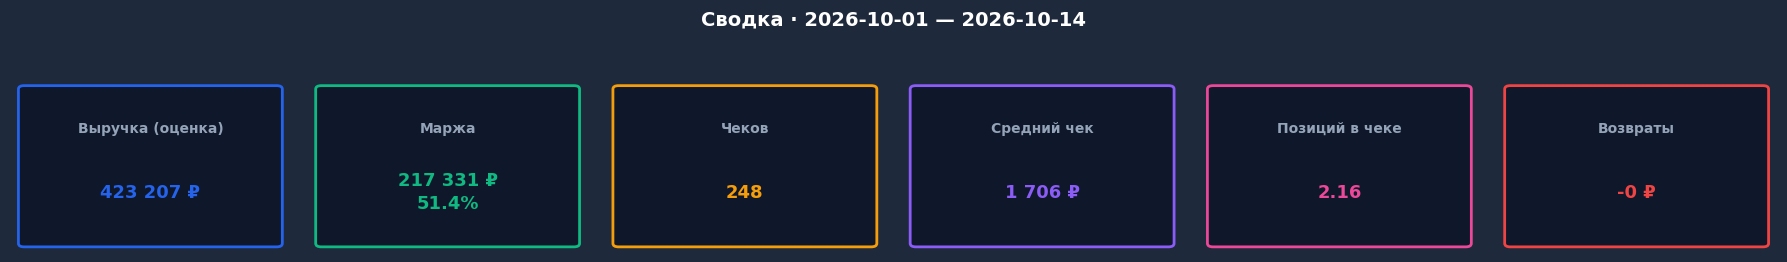

ℹ️  Маржинальность без «услуг флориста»: 48.1%  (с услугами: 51.4%)
ℹ️  Выручка в день (в среднем): 30 229 ₽


In [6]:
total_rev    = df['Выручка'].sum()
total_cost   = df['Себестоимость'].sum()
total_margin = total_rev - total_cost
margin_pct   = total_margin / total_rev * 100 if total_rev else 0
n_checks     = df_s['check_key'].nunique()
avg_check    = df_s.groupby('check_key')['Выручка'].sum().mean() if n_checks else 0
items_per_check = df_s.groupby('check_key').size().mean() if n_checks else 0
ret_rev      = -df.loc[df['Возврат'], 'Выручка'].sum()

# маржа без «услуг флориста» — честнее показывает торговую наценку
core = df[df['Категория'] != 'Услуги флориста']
core_margin_pct = (core['Выручка'].sum() - core['Себестоимость'].sum()) / core['Выручка'].sum() * 100 if core['Выручка'].sum() else 0

kpis = [
    ('Выручка (оценка)',  rub(total_rev),                                    '#2563EB'),
    ('Маржа',             f'{rub(total_margin)}\n{pct(margin_pct)}',         '#10B981'),
    ('Чеков',             num(n_checks),                                     '#F59E0B'),
    ('Средний чек',       rub(avg_check),                                    '#8B5CF6'),
    ('Позиций в чеке',    f'{items_per_check:.2f}',                          '#EC4899'),
    ('Возвраты',          rub(ret_rev),                                      '#EF4444'),
]

fig, axes = plt.subplots(1, len(kpis), figsize=(18, 2.4))
fig.patch.set_facecolor('#1E293B')
for ax, (label, value, color) in zip(axes, kpis):
    ax.set_facecolor('#1E293B')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis('off')
    ax.add_patch(mpatches.FancyBboxPatch((0.05, 0.05), 0.90, 0.90, boxstyle='round,pad=0.02',
                                         linewidth=2, edgecolor=color, facecolor='#0F172A'))
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=10, color='#94A3B8', fontweight='bold')
    ax.text(0.5, 0.35, value, ha='center', va='center', fontsize=13, color=color, fontweight='bold', linespacing=1.4)
fig.suptitle(f'Сводка · {_dmin.date()} — {_dmax.date()}', fontsize=14, fontweight='bold', color='white', y=1.08)
plt.tight_layout()
plt.show()

print(f'ℹ️  Маржинальность без «услуг флориста»: {pct(core_margin_pct)}  (с услугами: {pct(margin_pct)})')
print(f'ℹ️  Выручка в день (в среднем): {rub(total_rev / period_days)}')

## 📈 7. Динамика выручки и маржи

Столбики — по дням, линия — скользящее среднее за 7 дней (убирает «шум» дней недели). Подписаны 5 самых сильных дней.

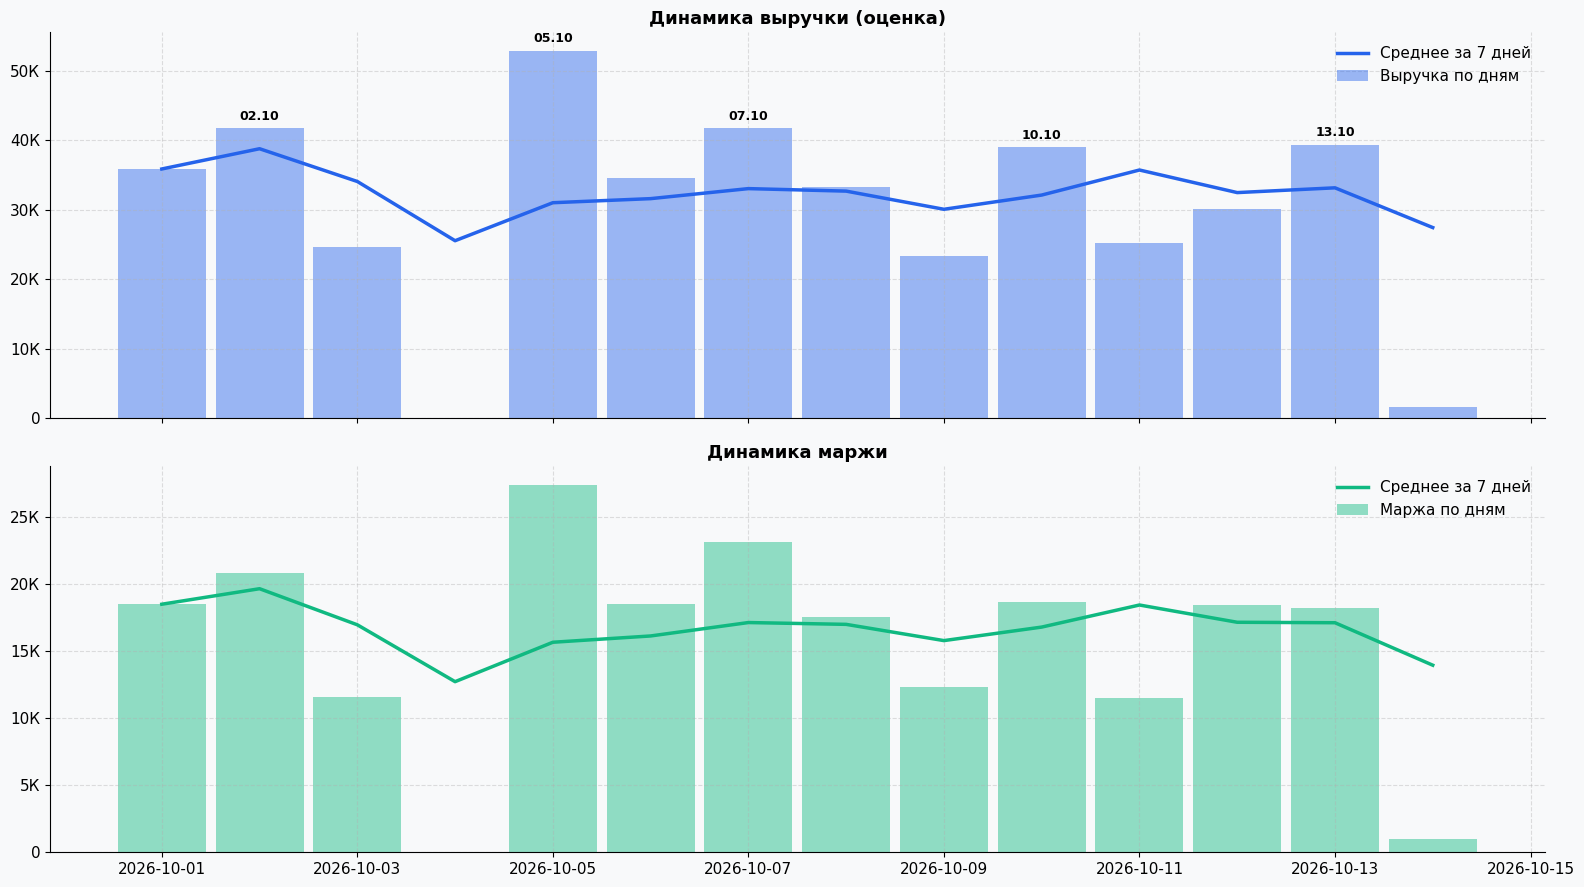

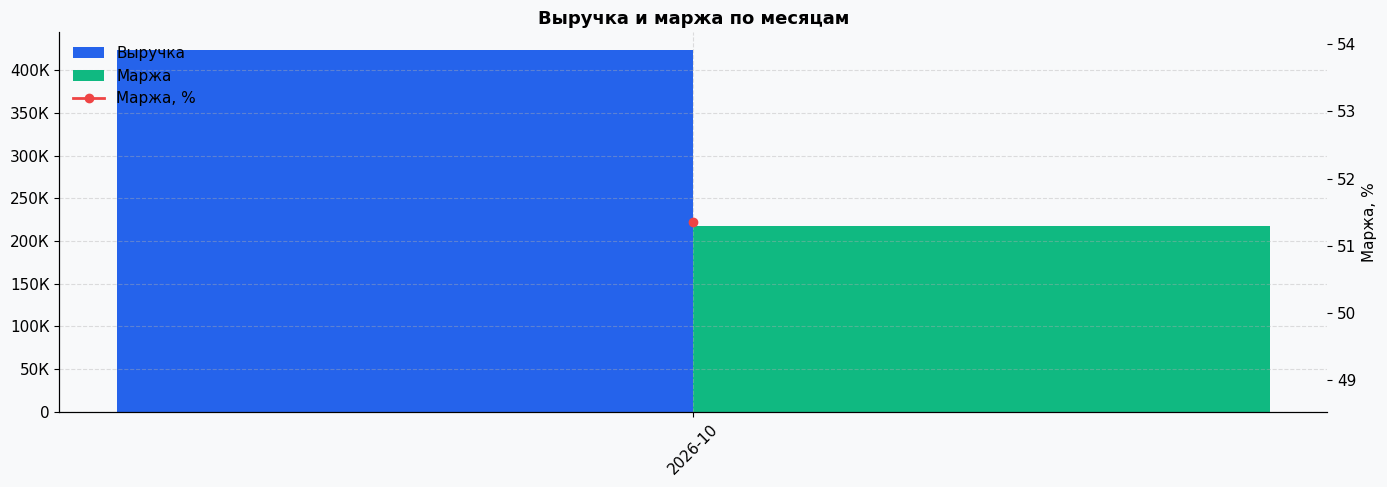

  Месяц   Выручка     Маржа Маржа, %  Чеков Средний чек
2026-10 423 207 ₽ 217 331 ₽    51.4%    248     1 706 ₽


In [7]:
daily = df.groupby('Дата').agg(Выручка=('Выручка', 'sum'), Маржа=('Маржа', 'sum')).reset_index()
daily['Чеков'] = daily['Дата'].map(df_s.groupby('Дата')['check_key'].nunique()).fillna(0)

# дни без продаж тоже нужны (как нули), иначе скользящее среднее врёт
calendar = pd.date_range(_dmin, _dmax, freq='D')
daily = daily.set_index('Дата').reindex(calendar, fill_value=0).rename_axis('Дата').reset_index()
daily['MA7']  = daily['Выручка'].rolling(7, min_periods=1).mean()
daily['MA7_m'] = daily['Маржа'].rolling(7, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
axes[0].bar(daily['Дата'], daily['Выручка'], color=PALETTE[0], alpha=0.45, width=0.9, label='Выручка по дням')
axes[0].plot(daily['Дата'], daily['MA7'], color=PALETTE[0], linewidth=2.5, label='Среднее за 7 дней')
for _, r in daily.nlargest(5, 'Выручка').iterrows():
    axes[0].annotate(r['Дата'].strftime('%d.%m'), xy=(r['Дата'], r['Выручка']), xytext=(0, 6),
                     textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
axes[0].set_title('Динамика выручки (оценка)')
axes[0].legend(frameon=False)

axes[1].bar(daily['Дата'], daily['Маржа'], color=PALETTE[1], alpha=0.45, width=0.9, label='Маржа по дням')
axes[1].plot(daily['Дата'], daily['MA7_m'], color=PALETTE[1], linewidth=2.5, label='Среднее за 7 дней')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
axes[1].set_title('Динамика маржи')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

# ---------- По месяцам ----------
monthly = df.groupby(df['Дата'].dt.to_period('M')).agg(Выручка=('Выручка', 'sum'), Маржа=('Маржа', 'sum')).reset_index()
monthly['Маржа, %'] = monthly['Маржа'] / monthly['Выручка'] * 100
monthly['Чеков'] = monthly['Дата'].map(df_s.groupby(df_s['Дата'].dt.to_period('M'))['check_key'].nunique())
monthly['Средний чек'] = monthly['Выручка'] / monthly['Чеков']
monthly['Месяц'] = monthly['Дата'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(monthly))
ax.bar(x - 0.2, monthly['Выручка'], width=0.4, color=PALETTE[0], label='Выручка')
ax.bar(x + 0.2, monthly['Маржа'], width=0.4, color=PALETTE[1], label='Маржа')
ax.set_xticks(x)
ax.set_xticklabels(monthly['Месяц'], rotation=45)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
ax2 = ax.twinx()
ax2.plot(x, monthly['Маржа, %'], color=PALETTE[3], marker='o', linewidth=2, label='Маржа, %')
ax2.set_ylabel('Маржа, %')
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc='upper left')
ax.set_title('Выручка и маржа по месяцам')
plt.tight_layout()
plt.show()

show = monthly[['Месяц', 'Выручка', 'Маржа', 'Маржа, %', 'Чеков', 'Средний чек']].copy()
show['Выручка'] = show['Выручка'].map(rub)
show['Маржа'] = show['Маржа'].map(rub)
show['Маржа, %'] = show['Маржа, %'].map(pct)
show['Средний чек'] = show['Средний чек'].map(rub)
print(show.to_string(index=False))

## 🎉 8. Праздники — главные пики цветочного бизнеса

Для каждого праздника берём дни перед ним (когда люди покупают) и сравниваем со **средним обычным днём**. Ниже — что именно покупали в эти дни: это готовый список для закупки к следующему году.

In [8]:
def holidays_for_year(y):
    nov30 = pd.Timestamp(y, 11, 30)
    mothers_day = nov30 - pd.Timedelta(days=(nov30.dayofweek + 1) % 7)   # последнее воскресенье ноября
    # (название, дата праздника, сколько дней до праздника входят в окно)
    return [
        ('1 сентября',        pd.Timestamp(y, 9, 1),   1),
        ('День матери',       mothers_day,             2),
        ('Новый год (31.12)', pd.Timestamp(y, 12, 31), 2),
        ('14 февраля',        pd.Timestamp(y, 2, 14),  2),
        ('23 февраля',        pd.Timestamp(y, 2, 23),  1),
        ('8 марта',           pd.Timestamp(y, 3, 8),   2),
    ]

normal_day = daily.loc[daily['Выручка'] > 0, 'Выручка'].median()
rows = []
for y in range(_dmin.year, _dmax.year + 1):
    for name, d, back in holidays_for_year(y):
        start = d - pd.Timedelta(days=back)
        if start < _dmin or d > _dmax:
            continue                       # окно не целиком в данных — пропускаем
        win = daily[(daily['Дата'] >= start) & (daily['Дата'] <= d)]
        rows.append({
            'Праздник': f'{name} {d.year}', 'Окно': f'{start:%d.%m}–{d:%d.%m}',
            'Выручка за окно': win['Выручка'].sum(),
            'В среднем за день': win['Выручка'].mean(),
            'Дней без чеков': int((win['Выручка'] == 0).sum()),
            '× к обычному дню': win['Выручка'].mean() / normal_day if normal_day else np.nan,
            'start': start, 'end': d,
        })
hol = pd.DataFrame(rows)

if len(hol) == 0:
    print('ℹ️ В выбранном периоде нет полных окон праздников.')
else:
    fig, ax = plt.subplots(figsize=(12, max(3, len(hol) * 0.7)))
    colors = [PALETTE[3] if v >= 2 else PALETTE[2] if v >= 1.3 else PALETTE[0] for v in hol['× к обычному дню']]
    ax.barh(hol['Праздник'][::-1], hol['× к обычному дню'][::-1], color=colors[::-1])
    for i, (v, gaps) in enumerate(zip(hol['× к обычному дню'][::-1], hol['Дней без чеков'][::-1])):
        ax.text(v + 0.03, i, f'×{v:.1f}' + ('  ⚠ в окне есть дни без чеков' if gaps else ''), va='center', fontweight='bold')
    ax.axvline(1, color='gray', linestyle='--')
    ax.set_title(f'Насколько праздничный день сильнее обычного (обычный день = {rub(normal_day)})')
    ax.set_xlim(0, hol['× к обычному дню'].max() * 1.2)
    plt.tight_layout()
    plt.show()

    for _, h in hol.iterrows():
        w = df_s[(df_s['Дата'] >= h['start']) & (df_s['Дата'] <= h['end'])]
        top = (w.groupby('Товар').agg(Продано=('Кол-во', 'sum'), Выручка=('Выручка', 'sum'))
                 .sort_values('Продано', ascending=False).head(8))
        warn = f'  ⚠️ дней без единого чека в окне: {h["Дней без чеков"]} — данные за праздник неполные' if h['Дней без чеков'] else ''
        print(f'\n🎁 {h["Праздник"]} ({h["Окно"]}): выручка {rub(h["Выручка за окно"])}, '
              f'×{h["× к обычному дню"]:.1f} к обычному дню{warn}')
        print('   Что покупали больше всего (шт.):  ' + ', '.join(f'{t} — {int(r.Продано)}' for t, r in top.iterrows()))

ℹ️ В выбранном периоде нет полных окон праздников.


## 🗓 9. Дни недели и часы

Слева — **средняя** выручка в этот день недели (а не сумма: иначе «длинные» дни выглядят лучше). Справа — карта «час × день недели»: когда магазин загружен.

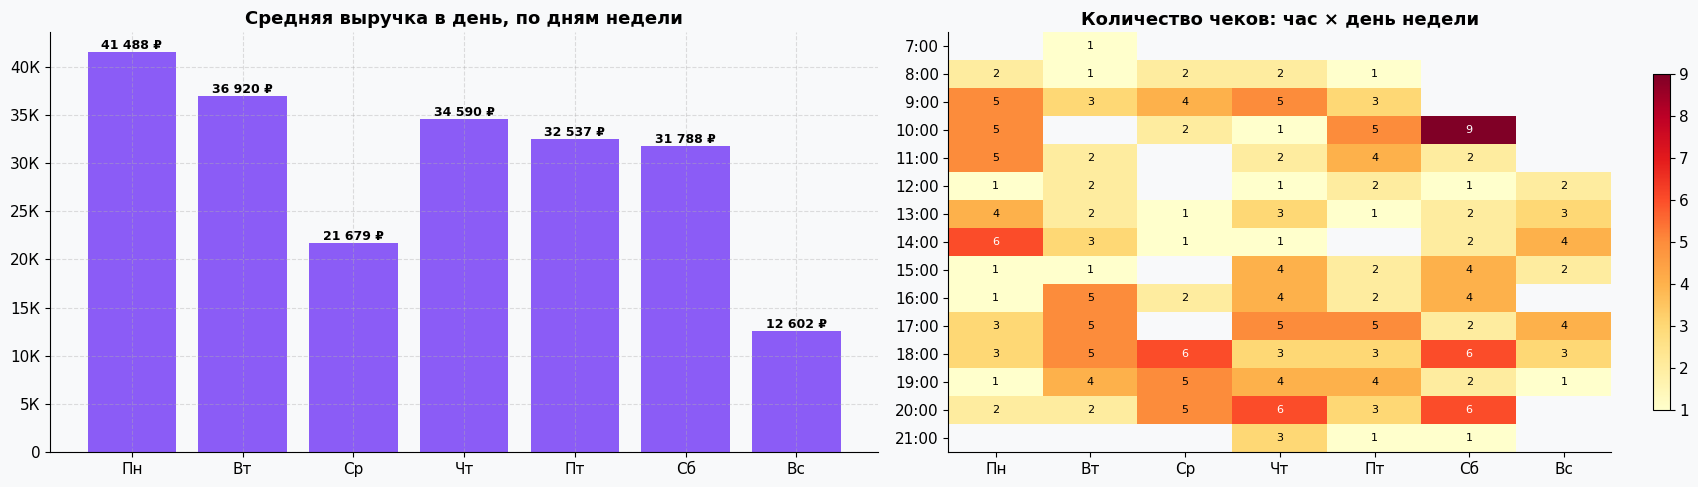

ℹ️ Чеков без указания времени (в карте часов не учтены): 2.0%
⏰ Самый загруженный час по чекам:    18:00
⏰ Самый выгодный час по выручке:     18:00
📅 Лучший день недели (в среднем):    Пн
📅 Слабейший день недели (в среднем): Вс


In [9]:
daily['День'] = daily['Дата'].dt.dayofweek
dow = daily.groupby('День').agg(Выручка=('Выручка', 'mean'), Чеков=('Чеков', 'mean')).reindex(range(7))

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].bar(DAYS_RU, dow['Выручка'], color=PALETTE[4])
for i, v in enumerate(dow['Выручка']):
    axes[0].text(i, v, rub(v), ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].set_title('Средняя выручка в день, по дням недели')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))

df_s['День'] = df_s['Дата'].dt.dayofweek
hm = (df_s.groupby(['Час', 'День'])['check_key'].nunique().unstack('День').reindex(columns=range(7)))
hm = hm.sort_index()
im = axes[1].imshow(hm.values.astype(float), cmap='YlOrRd', aspect='auto')
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(DAYS_RU)
axes[1].set_yticks(range(len(hm))); axes[1].set_yticklabels([f'{int(h)}:00' for h in hm.index])
vmax = np.nanmax(hm.values.astype(float)) if hm.size else 1
for i in range(hm.shape[0]):
    for j in range(7):
        v = hm.iloc[i, j]
        if not np.isnan(v):
            axes[1].text(j, i, int(v), ha='center', va='center', fontsize=8, color='white' if v > vmax * 0.6 else 'black')
axes[1].set_title('Количество чеков: час × день недели')
axes[1].grid(False)
plt.colorbar(im, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()

by_hour = df_s.dropna(subset=['Час']).groupby('Час').agg(Чеков=('check_key', 'nunique'), Выручка=('Выручка', 'sum'))
no_time = df_s['Час'].isna().groupby(df_s['check_key']).all().mean() * 100
print(f'ℹ️ Чеков без указания времени (в карте часов не учтены): {no_time:.1f}%')
print(f'⏰ Самый загруженный час по чекам:    {int(by_hour["Чеков"].idxmax())}:00')
print(f'⏰ Самый выгодный час по выручке:     {int(by_hour["Выручка"].idxmax())}:00')
print(f'📅 Лучший день недели (в среднем):    {DAYS_RU[int(dow["Выручка"].idxmax())]}')
print(f'📅 Слабейший день недели (в среднем): {DAYS_RU[int(dow["Выручка"].idxmin())]}')

## 🏆 10. ABC-анализ товаров

* **A** — товары, дающие первые 80% выручки (или маржи); **B** — следующие 15%; **C** — последние 5%.
* Считаем дважды: по **выручке** и по **марже**. Товар, у которого классы разные, — повод задуматься (много оборота, но мало прибыли, и наоборот).

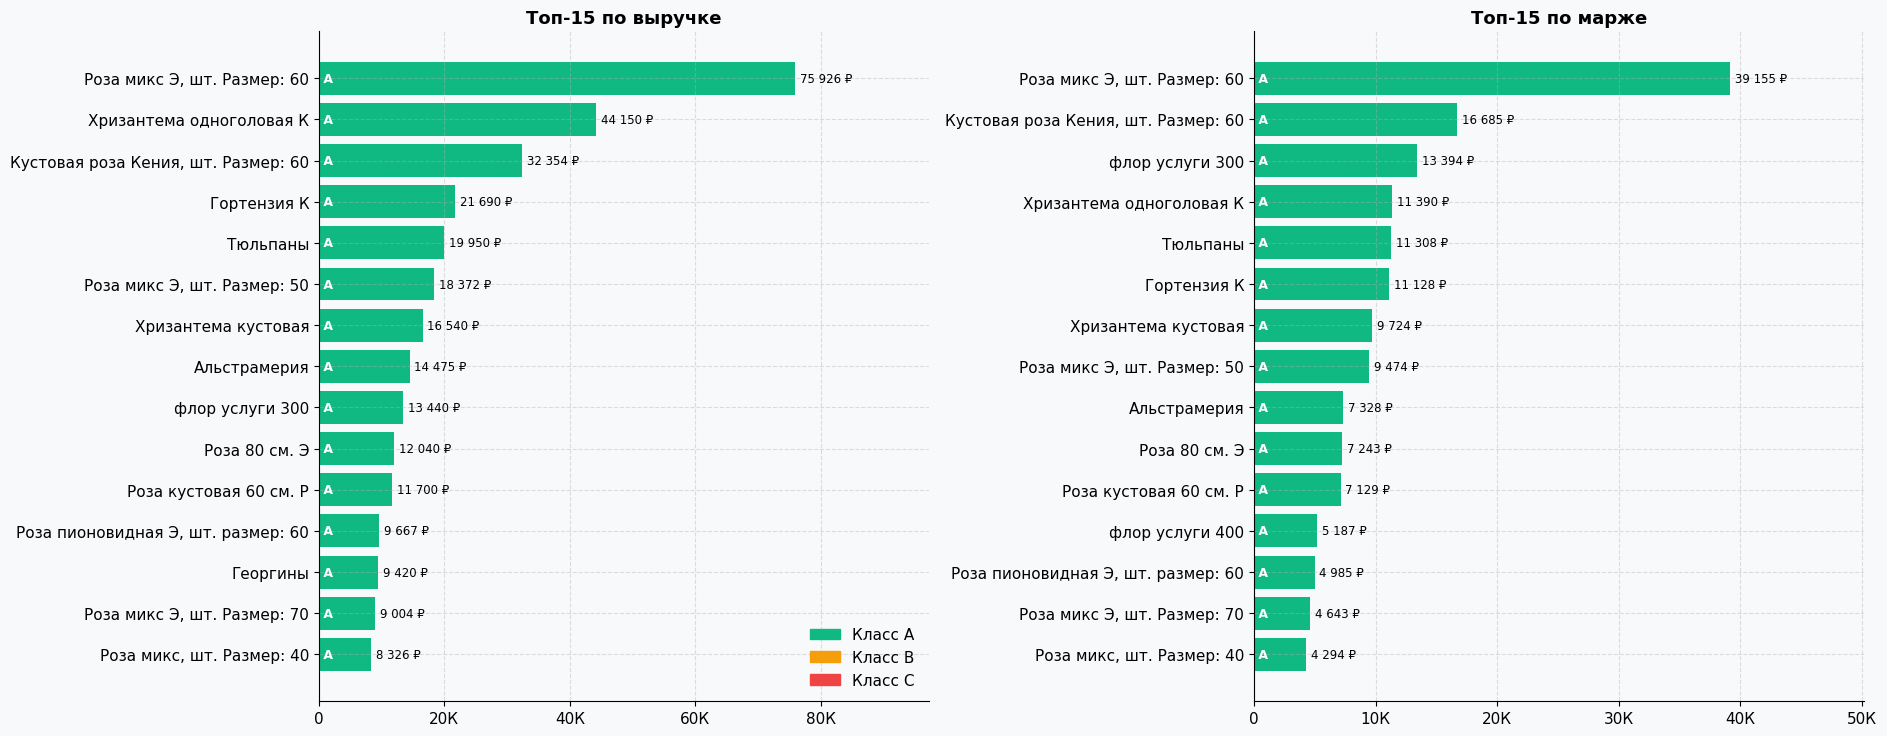


📊 ABC по выручке:
Класс  Товаров   Выручка     Маржа Доля товаров
    A       19 340 118 ₽ 174 865 ₽        26.4%
    B       20  62 661 ₽  32 633 ₽        27.8%
    C       33  20 428 ₽  10 183 ₽        45.8%

📊 ABC по марже:
Класс  Товаров   Выручка     Маржа Доля товаров
    A       19 338 218 ₽ 176 912 ₽        26.8%
    B       19  59 621 ₽  30 770 ₽        26.8%
    C       33  24 793 ₽  10 335 ₽        46.5%

🔄 Товаров, у которых класс по выручке ≠ классу по марже: 8. Самые крупные по выручке:
          Товар Класс (выручка) Выручка Маржа, % Класс (маржа)
    Протея люкс               A 6 000 ₽    33.5%             B
флор услуги 100               B 4 100 ₽    99.0%             A
          Алиум               B 3 600 ₽    14.0%             C
      Гелиантус               B 2 420 ₽    35.5%             C
      Грин трик               B 1 750 ₽    49.9%             C
  Сумки средние               C 1 480 ₽    78.8%             B
        Конверт               C 1 350 ₽    93.1%    

In [10]:
def abc_table(data, value_col):
    t = data.groupby('Товар').agg(Выручка=('Выручка', 'sum'), Маржа=('Маржа', 'sum'), Продано=('Кол-во', 'sum')).reset_index()
    t = t[t[value_col] > 0].sort_values(value_col, ascending=False).reset_index(drop=True)
    t['Доля, %'] = t[value_col] / t[value_col].sum() * 100
    t['Накопл., %'] = t['Доля, %'].cumsum()
    before = t['Накопл., %'] - t['Доля, %']        # доля, накопленная ДО этого товара
    t['Класс'] = np.where(before < 80, 'A', np.where(before < 95, 'B', 'C'))
    t['Маржа, %'] = np.where(t['Выручка'] > 0, t['Маржа'] / t['Выручка'] * 100, np.nan)
    return t

abc_rev = abc_table(df_s, 'Выручка')
abc_mar = abc_table(df_s, 'Маржа')

fig, axes = plt.subplots(1, 2, figsize=(19, max(6, TOP_N * 0.5)))
for ax, t, col, title in [(axes[0], abc_rev, 'Выручка', f'Топ-{TOP_N} по выручке'),
                          (axes[1], abc_mar, 'Маржа',   f'Топ-{TOP_N} по марже')]:
    top = t.head(TOP_N)[::-1]
    barh_labels(ax, top['Товар'], top[col], [ABC_COLORS[c] for c in top['Класс']], fmt=rub)
    for i, c in enumerate(top['Класс']):
        ax.text(0, i, f' {c}', va='center', fontsize=9, fontweight='bold', color='white')
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
axes[0].legend(handles=[mpatches.Patch(color=ABC_COLORS[c], label=f'Класс {c}') for c in 'ABC'], frameon=False)
plt.tight_layout()
plt.show()

for name, t in [('по выручке', abc_rev), ('по марже', abc_mar)]:
    s = t.groupby('Класс').agg(Товаров=('Товар', 'count'), Выручка=('Выручка', 'sum'), Маржа=('Маржа', 'sum')).reset_index()
    s['Доля товаров'] = (s['Товаров'] / s['Товаров'].sum() * 100).map(pct)
    s['Выручка'] = s['Выручка'].map(rub)
    s['Маржа'] = s['Маржа'].map(rub)
    print(f'\n📊 ABC {name}:')
    print(s.to_string(index=False))

cmp_ = abc_rev[['Товар', 'Класс', 'Выручка', 'Маржа, %']].merge(abc_mar[['Товар', 'Класс']], on='Товар', how='outer', suffixes=(' (выручка)', ' (маржа)'))
diff = cmp_[(cmp_['Класс (выручка)'] != cmp_['Класс (маржа)'])].sort_values('Выручка', ascending=False)
print(f'\n🔄 Товаров, у которых класс по выручке ≠ классу по марже: {len(diff)}. Самые крупные по выручке:')
d = diff.head(10).copy()
d['Выручка'] = d['Выручка'].map(rub)
d['Маржа, %'] = d['Маржа, %'].map(pct)
print(d.to_string(index=False))

## 📐 11. XYZ-анализ и матрица ABC-XYZ

**XYZ** показывает, насколько *стабилен* спрос на товар по неделям: коэффициент вариации CV = разброс / среднее.

* **X** — стабильный спрос (CV ≤ 0.5): можно держать запас;
* **Y** — колеблется (0.5 < CV ≤ 1.0);
* **Z** — нерегулярный/сезонный (CV > 1.0): закупать под заказ и под сезон.

Для цветов много Z — это нормально (сезонность), важно смотреть на **AZ**: прибыльные товары с непредсказуемым спросом — зона риска списаний.

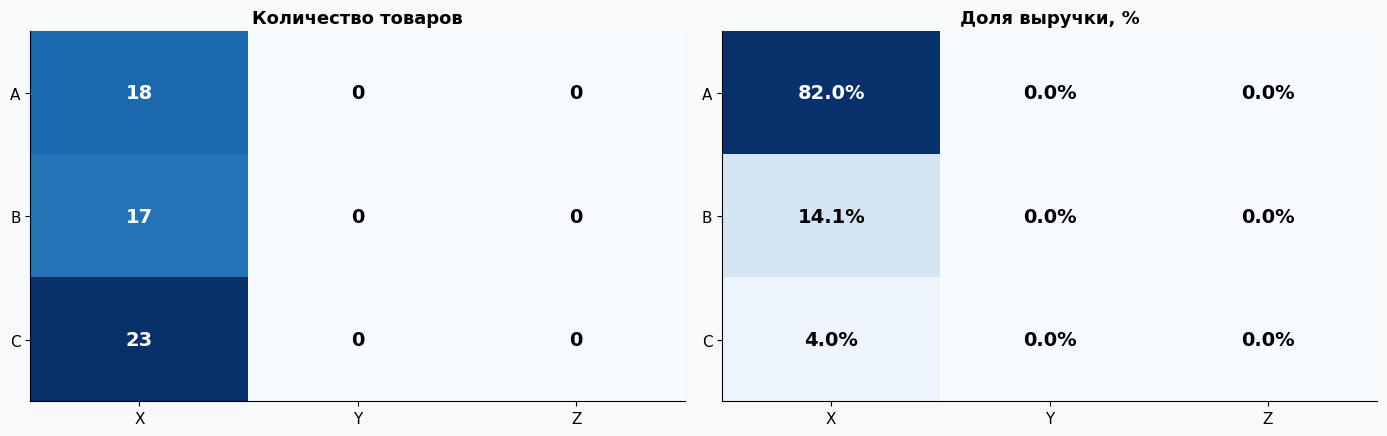

🔴 Зона риска — AZ и BZ (много выручки, спрос непредсказуем). Топ по выручке:
Empty DataFrame
Columns: [Товар, Группа, CV, Выручка]
Index: []

🟢 Опора ассортимента — AX и BX (стабильный спрос, можно держать неснижаемый остаток):
                              Товар Группа  CV  Выручка
        Роза микс Э, шт. Размер: 60     AX 0.0 75 926 ₽
           Хризантема одноголовая К     AX 0.0 44 150 ₽
Кустовая роза Кения, шт. Размер: 60     AX 0.0 32 354 ₽
                        Гортензия К     AX 0.0 21 690 ₽
                           Тюльпаны     AX 0.0 19 950 ₽
        Роза микс Э, шт. Размер: 50     AX 0.0 18 372 ₽
                Хризантема кустовая     AX 0.0 16 540 ₽
                       Альстрамерия     AX 0.0 14 475 ₽
                    флор услуги 300     AX 0.0 13 440 ₽
                      Роза 80 см. Э     AX 0.0 12 040 ₽


In [11]:
weekly = (df_s.assign(Неделя=df_s['Дата'] - pd.to_timedelta(df_s['Дата'].dt.dayofweek, unit='D'))
              .pivot_table(index='Товар', columns='Неделя', values='Кол-во', aggfunc='sum', fill_value=0))
if weekly.shape[1] > 2:
    weekly = weekly.iloc[:, 1:-1]            # отрезаем неполные недели по краям
mean_w = weekly.mean(axis=1)
cv = (weekly.std(axis=1, ddof=0) / mean_w.replace(0, np.nan)).rename('CV')
xyz = cv.dropna().reset_index()
xyz['XYZ'] = np.where(xyz['CV'] <= 0.5, 'X', np.where(xyz['CV'] <= 1.0, 'Y', 'Z'))

abcxyz = abc_rev[['Товар', 'Класс', 'Выручка']].merge(xyz[['Товар', 'CV', 'XYZ']], on='Товар', how='inner')
abcxyz['Группа'] = abcxyz['Класс'] + abcxyz['XYZ']

cnt = abcxyz.pivot_table(index='Класс', columns='XYZ', values='Товар', aggfunc='count', fill_value=0).reindex(index=list('ABC'), columns=list('XYZ'), fill_value=0)
revp = abcxyz.pivot_table(index='Класс', columns='XYZ', values='Выручка', aggfunc='sum', fill_value=0).reindex(index=list('ABC'), columns=list('XYZ'), fill_value=0)
revp = revp / revp.values.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, M, title, f in [(axes[0], cnt, 'Количество товаров', lambda v: f'{int(v)}'),
                        (axes[1], revp, 'Доля выручки, %', lambda v: f'{v:.1f}%')]:
    ax.imshow(M.values.astype(float), cmap='Blues', aspect='auto')
    ax.set_xticks(range(3)); ax.set_xticklabels(list('XYZ'))
    ax.set_yticks(range(3)); ax.set_yticklabels(list('ABC'))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f(M.values[i, j]), ha='center', va='center', fontsize=14, fontweight='bold',
                    color='white' if M.values[i, j] > M.values.max() * 0.55 else 'black')
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()
plt.show()

print('🔴 Зона риска — AZ и BZ (много выручки, спрос непредсказуем). Топ по выручке:')
risk = abcxyz[abcxyz['Группа'].isin(['AZ', 'BZ'])].sort_values('Выручка', ascending=False).head(10).copy()
risk['Выручка'] = risk['Выручка'].map(rub)
risk['CV'] = risk['CV'].round(2)
print(risk[['Товар', 'Группа', 'CV', 'Выручка']].to_string(index=False))

print('\n🟢 Опора ассортимента — AX и BX (стабильный спрос, можно держать неснижаемый остаток):')
base = abcxyz[abcxyz['Группа'].isin(['AX', 'BX'])].sort_values('Выручка', ascending=False).head(10).copy()
if len(base):
    base['Выручка'] = base['Выручка'].map(rub)
    base['CV'] = base['CV'].round(2)
    print(base[['Товар', 'Группа', 'CV', 'Выручка']].to_string(index=False))
else:
    print('   Таких товаров нет — спрос на ключевые позиции колеблется (характерно для срезанных цветов).')

## 📂 12. Категории

Категории определяются **автоматически по названию** товара (правила — в функции `categorize` выше; если товар попал не туда, добавьте слово в нужное правило).

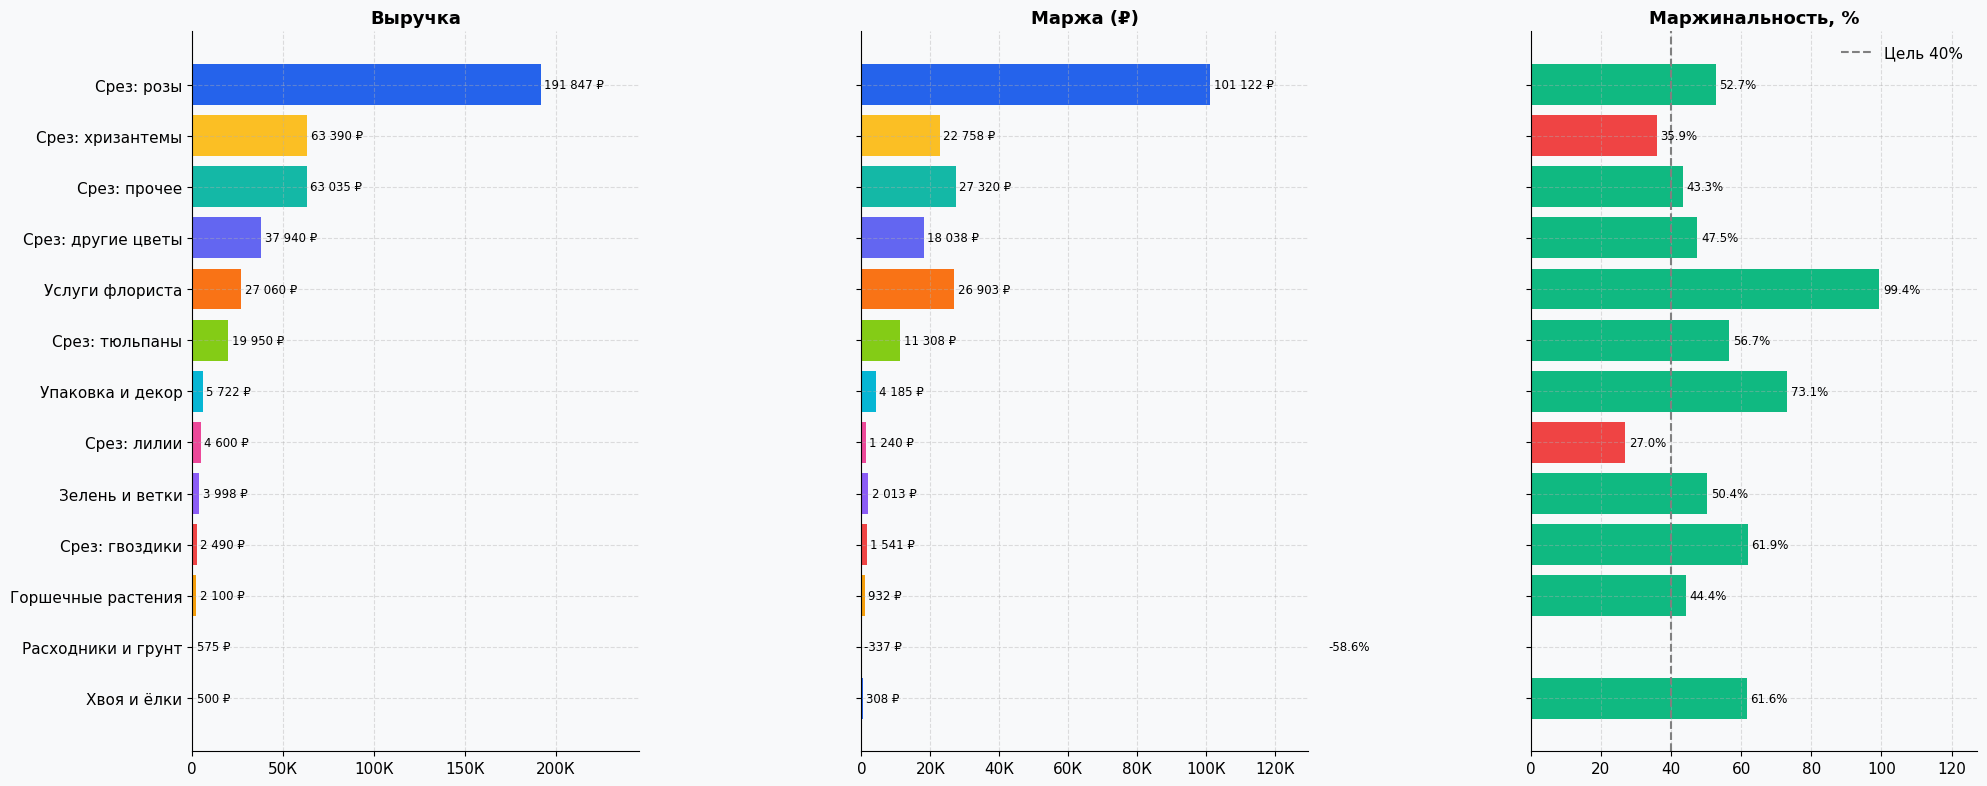

         Категория   Выручка     Маржа Продано Маржа, % Доля выручки, % Доля маржи, %
        Срез: розы 191 847 ₽ 101 122 ₽     915    52.7%           45.3%         46.5%
  Срез: хризантемы  63 390 ₽  22 758 ₽     328    35.9%           15.0%         10.5%
      Срез: прочее  63 035 ₽  27 320 ₽     303    43.3%           14.9%         12.6%
Срез: другие цветы  37 940 ₽  18 038 ₽     130    47.5%            9.0%          8.3%
   Услуги флориста  27 060 ₽  26 903 ₽     157    99.4%            6.4%         12.4%
    Срез: тюльпаны  19 950 ₽  11 308 ₽     133    56.7%            4.7%          5.2%
  Упаковка и декор   5 722 ₽   4 185 ₽      31    73.1%            1.4%          1.9%
       Срез: лилии   4 600 ₽   1 240 ₽      12    27.0%            1.1%          0.6%
    Зелень и ветки   3 998 ₽   2 013 ₽      38    50.4%            0.9%          0.9%
    Срез: гвоздики   2 490 ₽   1 541 ₽      18    61.9%            0.6%          0.7%
Горшечные растения   2 100 ₽     932 ₽       2    44.4

In [12]:
cat = df.groupby('Категория').agg(Выручка=('Выручка', 'sum'), Маржа=('Маржа', 'sum'), Продано=('Кол-во', 'sum')).reset_index()
cat['Маржа, %'] = np.where(cat['Выручка'] > 0, cat['Маржа'] / cat['Выручка'] * 100, np.nan)
cat['Доля выручки, %'] = cat['Выручка'] / cat['Выручка'].sum() * 100
cat['Доля маржи, %'] = cat['Маржа'] / cat['Маржа'].sum() * 100
cat = cat.sort_values('Выручка', ascending=True)

fig, axes = plt.subplots(1, 3, figsize=(20, max(5, len(cat) * 0.5 + 1.5)))
colors = [PALETTE[i % len(PALETTE)] for i in range(len(cat))]
barh_labels(axes[0], cat['Категория'], cat['Выручка'], colors)
axes[0].set_title('Выручка'); axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
barh_labels(axes[1], cat['Категория'], cat['Маржа'], colors)
axes[1].set_title('Маржа (₽)'); axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
axes[1].set_yticklabels([])
mc = [ABC_COLORS['A'] if (v >= MARGIN_TARGET) else ABC_COLORS['C'] for v in cat['Маржа, %'].fillna(0)]
barh_labels(axes[2], cat['Категория'], cat['Маржа, %'].fillna(0), mc, fmt=pct)
axes[2].axvline(MARGIN_TARGET, color='gray', linestyle='--', label=f'Цель {MARGIN_TARGET}%')
axes[2].set_title('Маржинальность, %'); axes[2].legend(frameon=False); axes[2].set_yticklabels([])
plt.tight_layout()
plt.show()

t = cat.sort_values('Выручка', ascending=False).copy()
t['Выручка'] = t['Выручка'].map(rub)
t['Маржа'] = t['Маржа'].map(rub)
t['Продано'] = t['Продано'].map(num)
for c in ['Маржа, %', 'Доля выручки, %', 'Доля маржи, %']:
    t[c] = t[c].map(pct)
print(t.to_string(index=False))

# Какие категории по «позиции» самые «неудобные» (много выручки, мало маржи)?
weak = cat[(cat['Доля выручки, %'] > cat['Доля выручки, %'].median()) & (cat['Маржа, %'] < MARGIN_TARGET)]
if len(weak):
    print('\n⚠️ Крупные категории с маржой ниже цели: ' + ', '.join(weak['Категория']))

## 🛒 13. Структура чека и допродажи

Сколько позиций берут за визит и как часто к цветам докупают упаковку, открытку, зелень или услугу флориста. Это прямой потенциал **апселла** (допродажи).

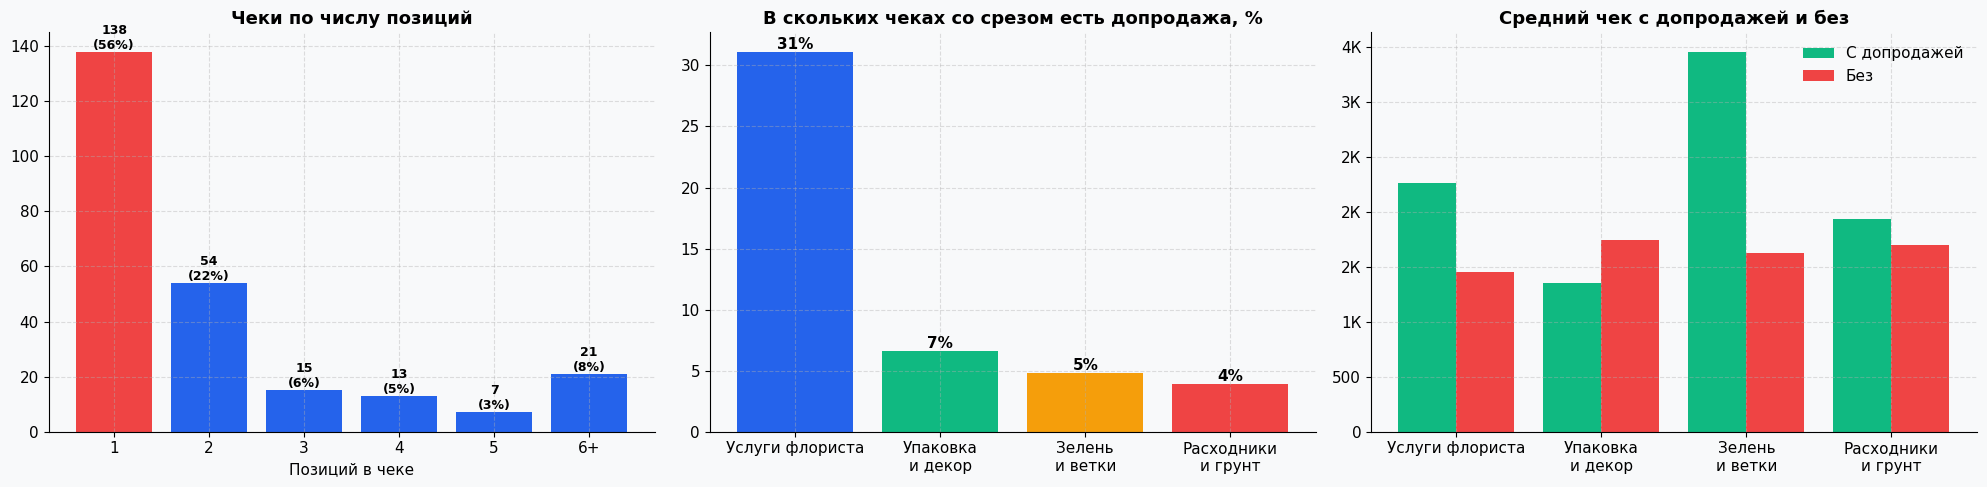

🧾 Чеков: 248; среднее позиций: 2.16; медиана: 1
🧾 Чеков с одной позицией: 55.6% — здесь основной потенциал допродажи
🧾 Средний чек: 1 706 ₽; медиана: 1 299 ₽ (большая разница = мало крупных чеков тянут среднее вверх)
   • Услуги флориста: чек 2 263 ₽ против 1 451 ₽ без неё
   • Упаковка и декор: чек 1 352 ₽ против 1 748 ₽ без неё
   • Зелень и ветки: чек 3 463 ₽ против 1 625 ₽ без неё
   • Расходники и грунт: чек 1 937 ₽ против 1 698 ₽ без неё


In [13]:
chk = df_s.groupby('check_key').agg(
    Выручка=('Выручка', 'sum'),
    Позиций=('Товар', 'count'),
    Штук=('Кол-во', 'sum'),
).reset_index()

# какие категории присутствуют в каждом чеке
pres = (df_s.assign(v=1).pivot_table(index='check_key', columns='Категория', values='v', aggfunc='max', fill_value=0))
chk = chk.merge(pres.reset_index(), on='check_key', how='left')

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
dist = chk['Позиций'].clip(upper=6).value_counts().sort_index()
labels = [str(i) if i < 6 else '6+' for i in dist.index]
axes[0].bar(labels, dist.values, color=[PALETTE[3] if l == '1' else PALETTE[0] for l in labels])
for i, v in enumerate(dist.values):
    axes[0].text(i, v, f'{v:,}\n({v / dist.sum() * 100:.0f}%)'.replace(',', ' '), ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].set_title('Чеки по числу позиций'); axes[0].set_xlabel('Позиций в чеке')

addon_cats = [c for c in ['Услуги флориста', 'Упаковка и декор', 'Зелень и ветки', 'Расходники и грунт'] if c in chk.columns]
flower_cols = [c for c in chk.columns if str(c).startswith('Срез')]
chk['Есть срез'] = chk[flower_cols].max(axis=1) if flower_cols else 0
with_flowers = chk[chk['Есть срез'] == 1]
attach = pd.Series({c: with_flowers[c].mean() * 100 for c in addon_cats})
axes[1].bar([c.replace(' и ', '\nи ') for c in attach.index], attach.values, color=PALETTE[:len(attach)])
for i, v in enumerate(attach.values):
    axes[1].text(i, v, f'{v:.0f}%', ha='center', va='bottom', fontweight='bold')
axes[1].set_title('В скольких чеках со срезом есть допродажа, %')

avg_with = [chk.loc[chk[c] == 1, 'Выручка'].mean() for c in addon_cats]
avg_wo = [chk.loc[chk[c] == 0, 'Выручка'].mean() for c in addon_cats]
x = np.arange(len(addon_cats))
axes[2].bar(x - 0.2, avg_with, width=0.4, color=PALETTE[1], label='С допродажей')
axes[2].bar(x + 0.2, avg_wo, width=0.4, color=PALETTE[3], label='Без')
axes[2].set_xticks(x); axes[2].set_xticklabels([c.replace(' и ', '\nи ') for c in addon_cats])
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
axes[2].set_title('Средний чек с допродажей и без'); axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

single = (chk['Позиций'] == 1).mean() * 100
print(f'🧾 Чеков: {num(len(chk))}; среднее позиций: {chk["Позиций"].mean():.2f}; медиана: {chk["Позиций"].median():.0f}')
print(f'🧾 Чеков с одной позицией: {single:.1f}% — здесь основной потенциал допродажи')
print(f'🧾 Средний чек: {rub(chk["Выручка"].mean())}; медиана: {rub(chk["Выручка"].median())} '
      f'(большая разница = мало крупных чеков тянут среднее вверх)')
for c in addon_cats:
    a = chk.loc[chk[c] == 1, 'Выручка'].mean()
    b = chk.loc[chk[c] == 0, 'Выручка'].mean()
    print(f'   • {c}: чек {rub(a)} против {rub(b)} без неё')

## 🧺 14. Market Basket — что покупают вместе

**Лифт** показывает, во сколько раз чаще два товара встречаются в одном чеке, чем если бы покупались независимо.

* Лифт > 2 — сильная связь (кандидаты в готовые наборы/комбо);
* 1.5–2 — хорошая связь;
* ≈ 1 — случайное сочетание.

Услуги флориста в анализ не включаем — они «прилипают» почти к любому чеку.

⚠️ Всего 241 чеков — выводы по корзине ориентировочные (нужно хотя бы 500–1000).


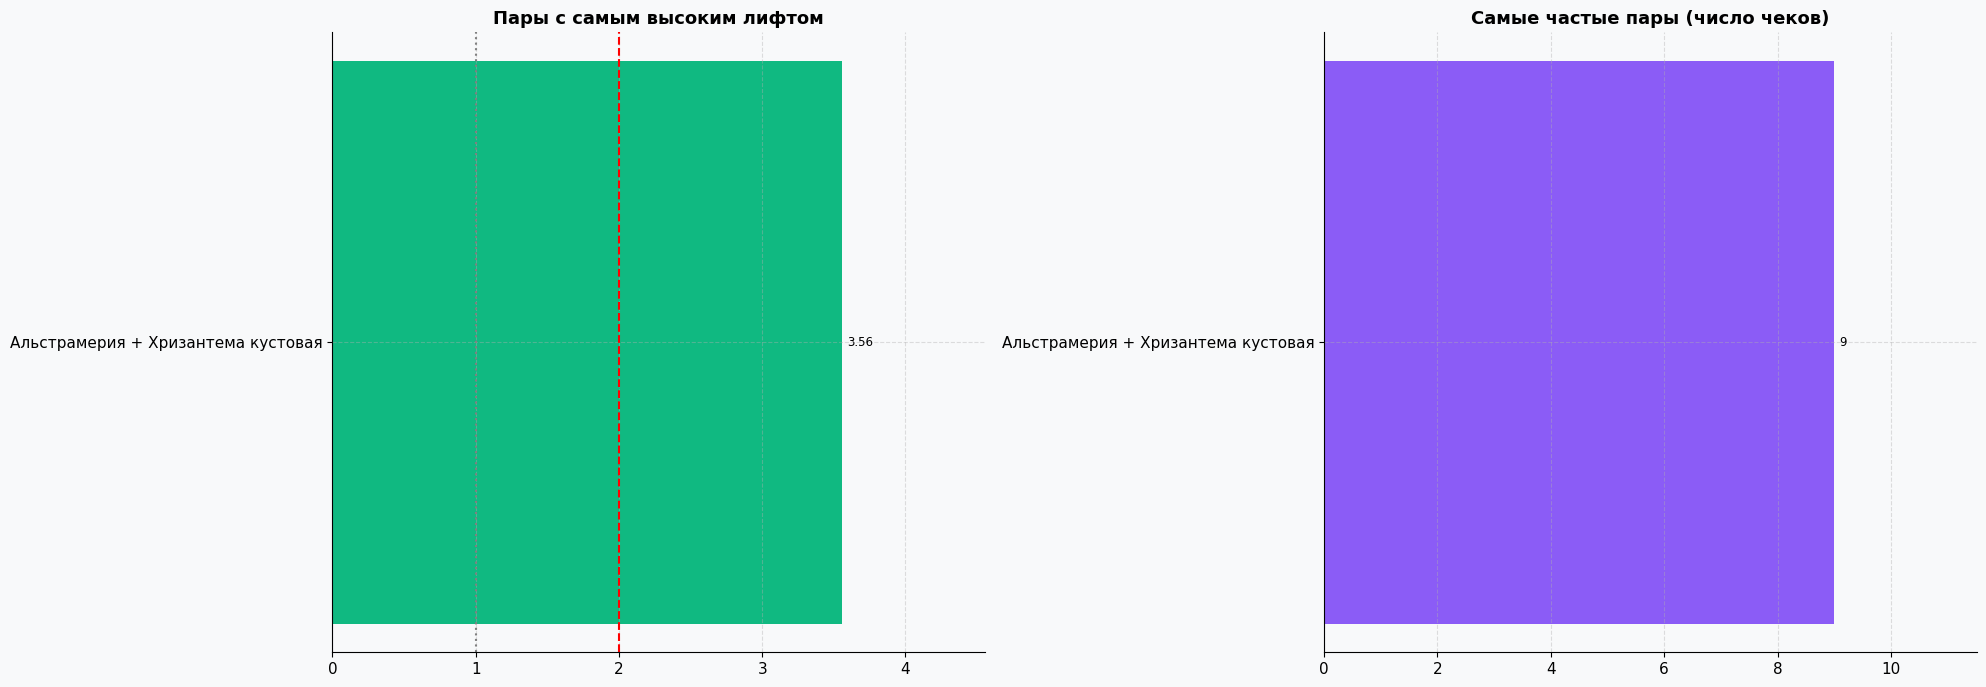

🔍 Чеков в анализе: 241; порог: пара минимум в 8 чеках; найдено пар: 1

Топ-10 по лифту (идеи для готовых наборов):
     Товар A             Товар B  Вместе  Поддержка, %  Лифт  Из чеков с A, %
Альстрамерия Хризантема кустовая       9          3.73  3.56             42.9

Топ-10 по частоте (что реально берут вместе чаще всего):
     Товар A             Товар B  Вместе  Поддержка, %  Лифт  Из чеков с A, %
Альстрамерия Хризантема кустовая       9          3.73  3.56             42.9


In [14]:
bk = df_s[df_s['Категория'] != 'Услуги флориста']
baskets = bk.groupby('check_key')['Товар'].apply(set)
n_b = len(baskets)
min_count = max(8, int(MIN_SUPPORT * n_b))

pair_cnt, single_cnt = Counter(), Counter()
for items in baskets:
    for it in items:
        single_cnt[it] += 1
    if len(items) >= 2:
        for pair in combinations(sorted(items), 2):
            pair_cnt[pair] += 1

rows = []
for (a, b), c in pair_cnt.items():
    if c >= min_count:
        lift = (c / n_b) / ((single_cnt[a] / n_b) * (single_cnt[b] / n_b))
        rows.append({'Товар A': a, 'Товар B': b, 'Вместе': c,
                     'Поддержка, %': round(c / n_b * 100, 2), 'Лифт': round(lift, 2),
                     'Из чеков с A, %': round(c / single_cnt[a] * 100, 1)})
pairs = pd.DataFrame(rows)

if n_b < 500:
    print(f'⚠️ Всего {n_b} чеков — выводы по корзине ориентировочные (нужно хотя бы 500–1000).')

if len(pairs) == 0:
    print(f'Нет пар, которые встречались бы вместе минимум {min_count} раз. Уменьшите MIN_SUPPORT.')
else:
    pairs = pairs.sort_values('Лифт', ascending=False).reset_index(drop=True)
    top_l = pairs.head(15).copy(); top_l['Пара'] = top_l['Товар A'] + ' + ' + top_l['Товар B']
    top_f = pairs.sort_values('Вместе', ascending=False).head(15).copy(); top_f['Пара'] = top_f['Товар A'] + ' + ' + top_f['Товар B']

    fig, axes = plt.subplots(1, 2, figsize=(20, 7))
    lc = [ABC_COLORS['A'] if v >= 2 else ABC_COLORS['B'] if v >= 1.5 else ABC_COLORS['C'] for v in top_l['Лифт'][::-1]]
    barh_labels(axes[0], top_l['Пара'][::-1], top_l['Лифт'][::-1], lc, fmt=lambda v: f'{v:.2f}')
    axes[0].axvline(1, color='gray', linestyle=':'); axes[0].axvline(2, color='red', linestyle='--')
    axes[0].set_title('Пары с самым высоким лифтом')
    barh_labels(axes[1], top_f['Пара'][::-1], top_f['Вместе'][::-1], [PALETTE[4]] * len(top_f), fmt=num)
    axes[1].set_title('Самые частые пары (число чеков)')
    plt.tight_layout()
    plt.show()

    print(f'🔍 Чеков в анализе: {num(n_b)}; порог: пара минимум в {min_count} чеках; найдено пар: {len(pairs)}')
    print('\nТоп-10 по лифту (идеи для готовых наборов):')
    print(pairs.head(10).to_string(index=False))
    print('\nТоп-10 по частоте (что реально берут вместе чаще всего):')
    print(pairs.sort_values('Вместе', ascending=False).head(10).to_string(index=False))

## 🌤 15. Сезонность товаров (месяц × товар)

Цветы сильно зависят от сезона, поэтому смотрим, **в какие месяцы** продаётся каждый из ведущих товаров. Цвет — доля от максимума продаж этого товара (1.0 = лучший месяц товара). Так видно, чем «живёт» магазин зимой, а чем летом.

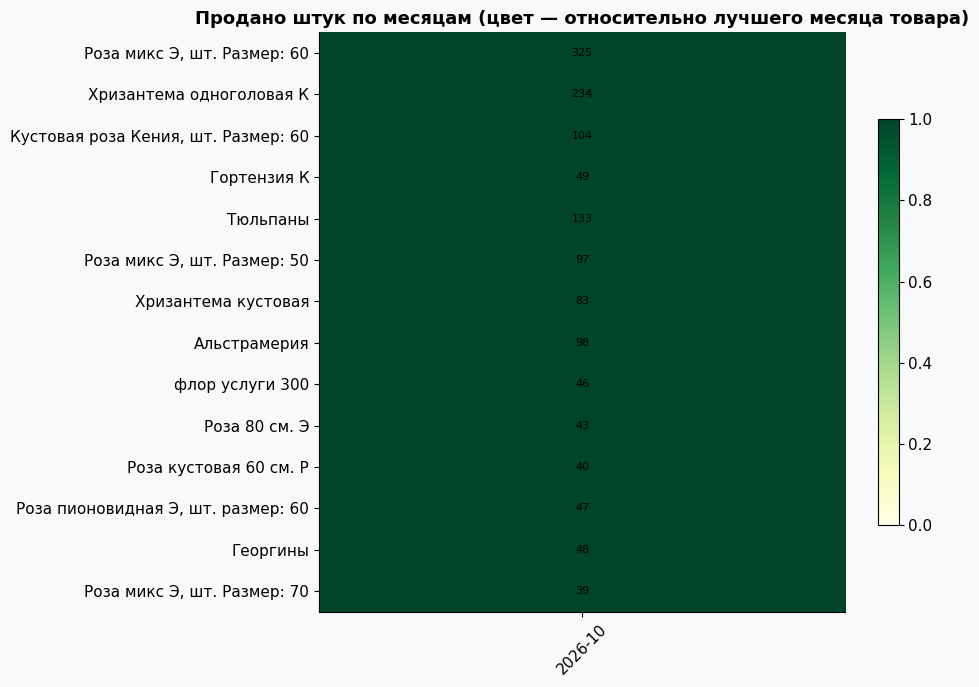

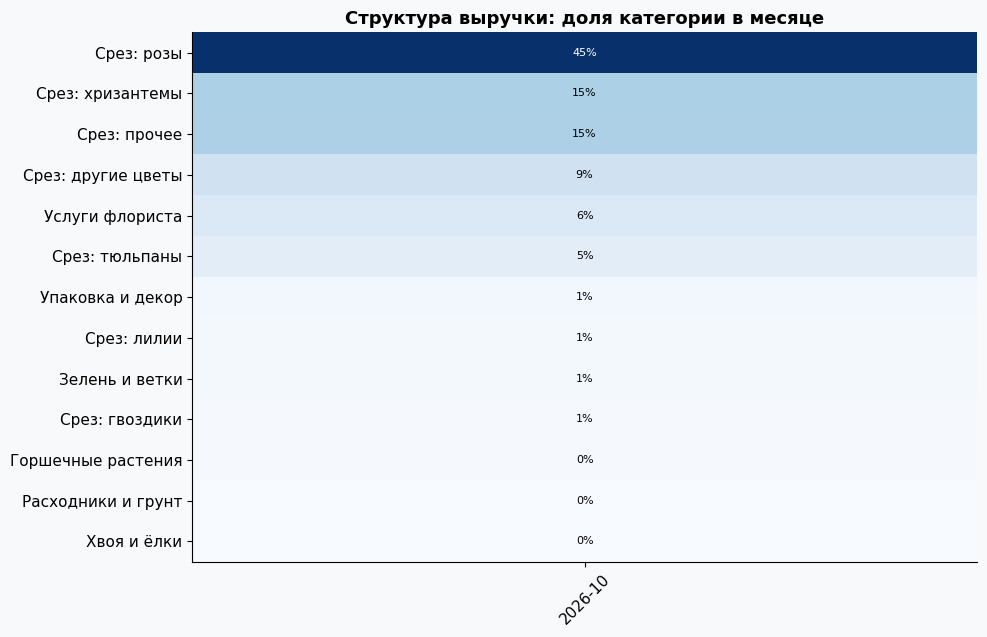

In [15]:
top_items = abc_rev.head(14)['Товар'].tolist()
sea = (df_s[df_s['Товар'].isin(top_items)].assign(Месяц=lambda d: d['Дата'].dt.to_period('M').astype(str))
           .pivot_table(index='Товар', columns='Месяц', values='Кол-во', aggfunc='sum', fill_value=0))
sea = sea.reindex(top_items)
norm = sea.div(sea.max(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(max(10, sea.shape[1] * 1.0), max(5, len(sea) * 0.5)))
im = ax.imshow(norm.values.astype(float), cmap='YlGn', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(sea.shape[1])); ax.set_xticklabels(sea.columns, rotation=45)
ax.set_yticks(range(len(sea))); ax.set_yticklabels(sea.index)
for i in range(sea.shape[0]):
    for j in range(sea.shape[1]):
        ax.text(j, i, int(sea.iloc[i, j]), ha='center', va='center', fontsize=8)
ax.set_title('Продано штук по месяцам (цвет — относительно лучшего месяца товара)')
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()

# Сезонность по категориям (доля выручки категории в месяце)
cm = (df.assign(Месяц=df['Дата'].dt.to_period('M').astype(str))
        .pivot_table(index='Категория', columns='Месяц', values='Выручка', aggfunc='sum', fill_value=0))
share = cm.div(cm.sum(axis=0), axis=1) * 100
share = share.loc[cat.sort_values('Выручка', ascending=False)['Категория']]
fig, ax = plt.subplots(figsize=(max(10, share.shape[1] * 1.0), max(4, len(share) * 0.5)))
im = ax.imshow(share.values.astype(float), cmap='Blues', aspect='auto')
ax.set_xticks(range(share.shape[1])); ax.set_xticklabels(share.columns, rotation=45)
ax.set_yticks(range(len(share))); ax.set_yticklabels(share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f'{share.iloc[i, j]:.0f}%', ha='center', va='center', fontsize=8,
                color='white' if share.iloc[i, j] > share.values.max() * 0.6 else 'black')
ax.set_title('Структура выручки: доля категории в месяце')
ax.grid(False)
plt.tight_layout()
plt.show()

## 🧭 16. Матрица BCG (рост × доля)

**Ось X** — доля товара в выручке, **ось Y** — рост выручки: вторая половина периода против первой.

* 🌟 **Звёзды** — большая доля и рост → развивать;
* 🐄 **Дойные коровы** — большая доля, нет роста → беречь маржу и наличие;
* ❓ **Вопросы** — малая доля, но растут → пробовать усиливать;
* 🐕 **Собаки** — малая доля, нет роста → пересмотреть/убрать.

⚠️ В цветах рост сильно смешан с сезоном (тюльпаны весной «растут» сами по себе). Матрицу лучше смотреть **за год и больше**.

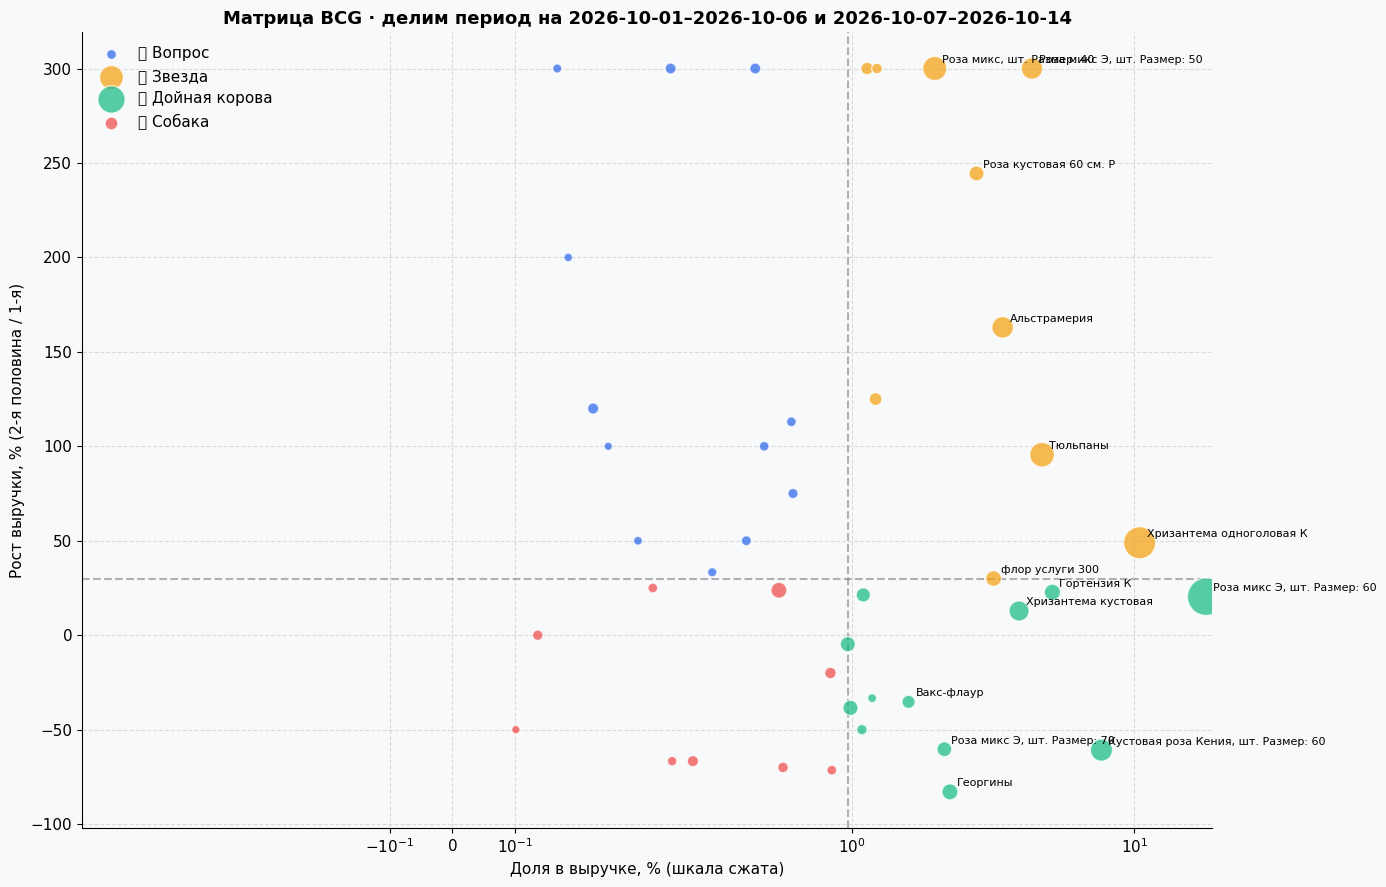

       Квадрант  Товаров   Выручка Доля выручки
       ❓ Вопрос       12  19 289 ₽         5.1%
       🌟 Звезда       10 145 552 ₽        38.7%
🐄 Дойная корова       12 194 201 ₽        51.6%
       🐕 Собака        9  17 372 ₽         4.6%

🌟 Звезда — топ-5 по выручке:
   • Хризантема одноголовая К                  44 150 ₽   рост +49%
   • Тюльпаны                                  19 950 ₽   рост +96%
   • Роза микс Э, шт. Размер: 50               18 372 ₽   рост +400%
   • Альстрамерия                              14 475 ₽   рост +163%
   • флор услуги 300                           13 440 ₽   рост +30%

🐄 Дойная корова — топ-5 по выручке:
   • Роза микс Э, шт. Размер: 60               75 926 ₽   рост +20%
   • Кустовая роза Кения, шт. Размер: 60       32 354 ₽   рост -61%
   • Гортензия К                               21 690 ₽   рост +23%
   • Хризантема кустовая                       16 540 ₽   рост +13%
   • Георгины                                   9 420 ₽   рост -83%

🐕 Собака —

In [16]:
dates_sorted = df_s['Дата'].sort_values()
mid = dates_sorted.iloc[len(dates_sorted) // 2]
r1 = df_s[df_s['Дата'] < mid].groupby('Товар')['Выручка'].sum()
r2 = df_s[df_s['Дата'] >= mid].groupby('Товар')['Выручка'].sum()
tot = df_s.groupby('Товар').agg(Выручка=('Выручка', 'sum'), Продаж=('Кол-во', 'sum'))

bcg = tot.join(r1.rename('R1')).join(r2.rename('R2')).fillna(0).reset_index()
bcg = bcg[bcg['Выручка'] > 0].copy()
bcg['Доля, %'] = bcg['Выручка'] / bcg['Выручка'].sum() * 100
bcg['Рост, %'] = np.where(bcg['R1'] > 0, (bcg['R2'] - bcg['R1']) / bcg['R1'] * 100, np.where(bcg['R2'] > 0, 300.0, 0.0))
bcg['Рост_clip'] = bcg['Рост, %'].clip(-100, 300)

# Берём только товары, у которых был хоть какой-то оборот в обеих половинах — иначе «рост» бессмыслен
active = bcg[(bcg['R1'] > 0) & (bcg['R2'] > 0)].copy()
med_share = active['Доля, %'].median()
med_growth = active['Рост_clip'].median()

def quad(r):
    hs, hg = r['Доля, %'] >= med_share, r['Рост_clip'] >= med_growth
    return '🌟 Звезда' if hs and hg else '🐄 Дойная корова' if hs else '❓ Вопрос' if hg else '🐕 Собака'
active['Квадрант'] = active.apply(quad, axis=1)
qcol = {'🌟 Звезда': PALETTE[2], '🐄 Дойная корова': PALETTE[1], '❓ Вопрос': PALETTE[0], '🐕 Собака': PALETTE[3]}

fig, ax = plt.subplots(figsize=(14, 9))
for q, g in active.groupby('Квадрант'):
    sizes = (g['Продаж'].clip(lower=0) / max(active['Продаж'].max(), 1) * 700 + 30)
    ax.scatter(g['Доля, %'], g['Рост_clip'], s=sizes, color=qcol[q], alpha=0.7, edgecolors='white', label=q, zorder=3)
for _, r in active.nlargest(14, 'Выручка').iterrows():
    ax.annotate(r['Товар'], (r['Доля, %'], r['Рост_clip']), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.axvline(med_share, color='gray', linestyle='--', alpha=0.6)
ax.axhline(med_growth, color='gray', linestyle='--', alpha=0.6)
ax.set_xscale('symlog', linthresh=0.5)
ax.set_xlabel('Доля в выручке, % (шкала сжата)')
ax.set_ylabel('Рост выручки, % (2-я половина / 1-я)')
ax.set_title(f'Матрица BCG · делим период на {_dmin.date()}–{(mid - pd.Timedelta(days=1)).date()} и {mid.date()}–{_dmax.date()}')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

s = active.groupby('Квадрант').agg(Товаров=('Товар', 'count'), Выручка=('Выручка', 'sum')).reset_index()
s['Доля выручки'] = (s['Выручка'] / s['Выручка'].sum() * 100).map(pct)
s['Выручка'] = s['Выручка'].map(rub)
print(s.to_string(index=False))
for q in ['🌟 Звезда', '🐄 Дойная корова', '🐕 Собака']:
    g = active[active['Квадрант'] == q].nlargest(5, 'Выручка')
    if len(g):
        print(f'\n{q} — топ-5 по выручке:')
        for _, r in g.iterrows():
            print(f'   • {r["Товар"]:<35} {rub(r["Выручка"]):>14}   рост {r["Рост, %"]:+.0f}%')
print(f'\nℹ️ Исключено товаров без продаж в одной из половин периода (сезонные/новые/выведенные): {len(bcg) - len(active)}')

## 💹 17. Цены и маржа: где теряем деньги

Ищем три проблемы:
1. **Много оборота, мало маржи** — товары, которые «крутятся», но почти не зарабатывают;
2. **Продажа ниже себестоимости или с нулевой маржой**;
3. **Нулевая себестоимость** — скорее всего, ошибка в приходе: маржа по таким товарам нарисована.

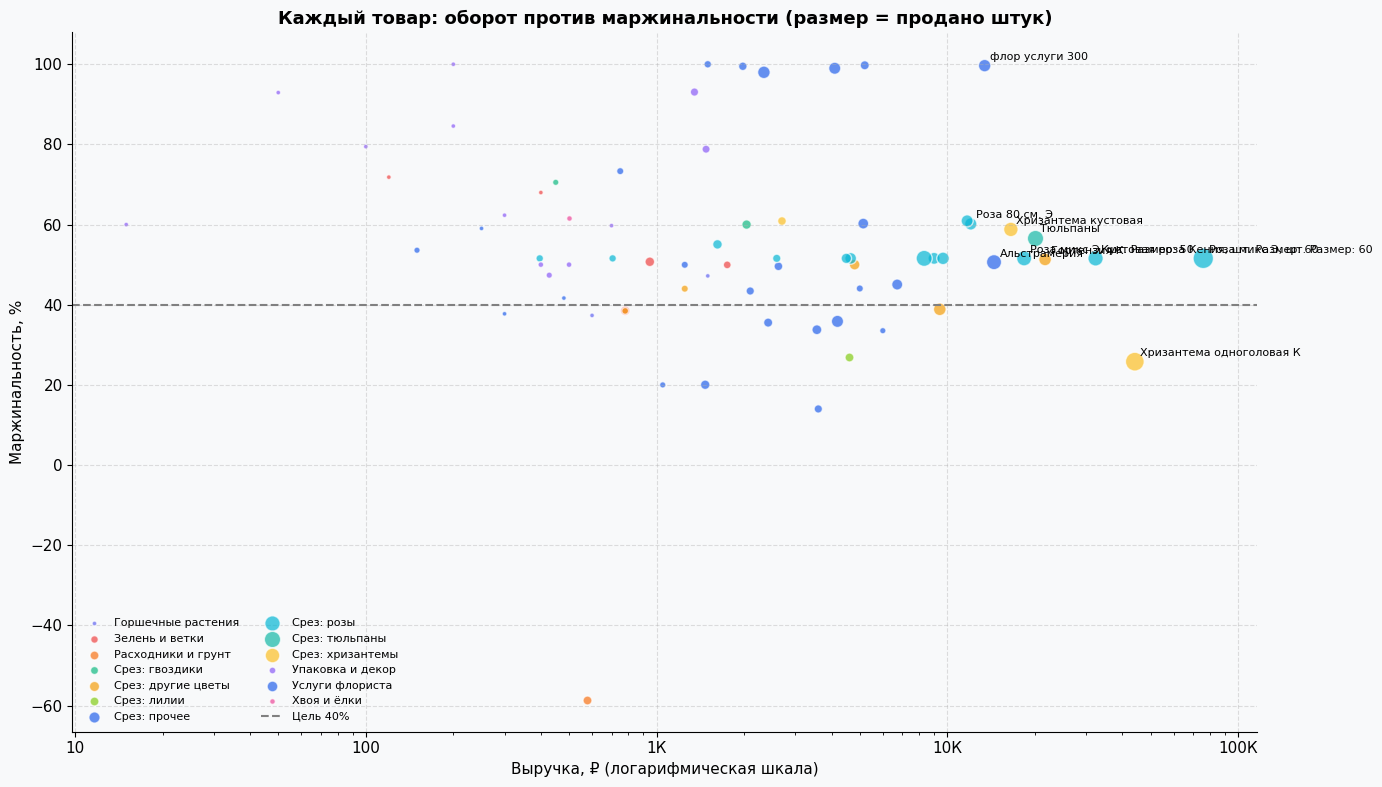

🟠 Крупные товары (верхние 25% по выручке) с маржой ниже 40%: 3
                   Товар          Категория  Выручка Маржа, % Продано
Хризантема одноголовая К   Срез: хризантемы 44 150 ₽    25.8%     234
                Георгины Срез: другие цветы  9 420 ₽    38.9%      48
             Протея люкс       Срез: прочее  6 000 ₽    33.5%       3

💡 Если довести эти товары до маржи 40% при тех же продажах — ≈ +6 766 ₽ к марже за период (грубая оценка, без учёта падения спроса при росте цены).

🔴 Товаров с нулевой/отрицательной маржой: 1
Товар Выручка Себестоимость  Продано
Оазис   575 ₽         912 ₽     12.0

⚪ Товаров, проданных с нулевой себестоимостью (проверьте приход!): 2
                              Товар Выручка  Продано
                        Оксипеталум 1 500 ₽      6.0
Грунт для декоративно-лиственных 5л   200 ₽      1.0


In [17]:
pm = df_s.groupby('Товар').agg(Выручка=('Выручка', 'sum'), Маржа=('Маржа', 'sum'), Продано=('Кол-во', 'sum'),
                              Себестоимость=('Себестоимость', 'sum')).reset_index()
pm = pm[pm['Выручка'] > 0].copy()
pm['Маржа, %'] = pm['Маржа'] / pm['Выручка'] * 100
pm['Категория'] = pm['Товар'].map(cat_map)
cats = pm['Категория'].unique().tolist()
ccol = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(cats)}

fig, ax = plt.subplots(figsize=(14, 8))
for c, g in pm.groupby('Категория'):
    ax.scatter(g['Выручка'], g['Маржа, %'], s=np.sqrt(g['Продано'].clip(lower=1)) * 12, color=ccol[c], alpha=0.7,
               edgecolors='white', label=c)
ax.set_xscale('log')
ax.axhline(MARGIN_TARGET, color='gray', linestyle='--', label=f'Цель {MARGIN_TARGET}%')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
for _, r in pm.nlargest(10, 'Выручка').iterrows():
    ax.annotate(r['Товар'], (r['Выручка'], r['Маржа, %']), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Выручка, ₽ (логарифмическая шкала)')
ax.set_ylabel('Маржинальность, %')
ax.set_title('Каждый товар: оборот против маржинальности (размер = продано штук)')
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

big = pm['Выручка'].quantile(0.75)
low = pm[(pm['Выручка'] >= big) & (pm['Маржа, %'] < MARGIN_TARGET)].sort_values('Выручка', ascending=False)
print(f'🟠 Крупные товары (верхние 25% по выручке) с маржой ниже {MARGIN_TARGET}%: {len(low)}')
t = low.head(12)[['Товар', 'Категория', 'Выручка', 'Маржа, %', 'Продано']].copy()
t['Выручка'] = t['Выручка'].map(rub); t['Маржа, %'] = t['Маржа, %'].map(pct); t['Продано'] = t['Продано'].map(num)
print(t.to_string(index=False))
if len(low):
    # сколько денег дало бы повышение цены этих товаров
    gap = ((MARGIN_TARGET / 100 - low['Маржа, %'] / 100).clip(lower=0) * low['Выручка']).sum()
    print(f'\n💡 Если довести эти товары до маржи {MARGIN_TARGET}% при тех же продажах — ≈ +{rub(gap)} к марже за период '
          f'(грубая оценка, без учёта падения спроса при росте цены).')

below = pm[pm['Маржа'] <= 0].sort_values('Выручка', ascending=False)
print(f'\n🔴 Товаров с нулевой/отрицательной маржой: {len(below)}')
if len(below):
    t = below.head(10)[['Товар', 'Выручка', 'Себестоимость', 'Продано']].copy()
    t['Выручка'] = t['Выручка'].map(rub); t['Себестоимость'] = t['Себестоимость'].map(rub)
    print(t.to_string(index=False))

zc = pm[(pm['Себестоимость'] <= 0)].sort_values('Выручка', ascending=False)
print(f'\n⚪ Товаров, проданных с нулевой себестоимостью (проверьте приход!): {len(zc)}')
if len(zc):
    t = zc.head(10)[['Товар', 'Выручка', 'Продано']].copy()
    t['Выручка'] = t['Выручка'].map(rub)
    print(t.to_string(index=False))

## 📦 18. Остатки и «мёртвый» товар

Цветы — скоропортящийся товар: лежачий остаток = будущее списание. Показываем:

* **Заморожено в остатках** — сколько денег лежит на складе;
* **Не продаётся** — есть остаток, но давно нет продаж (порог — `SLOW_DAYS`);
* **Оборачиваемость (sell-through)** = продано / (начальный остаток + приход): низкая доля = закупаем больше, чем продаём;
* **Отрицательные остатки** — ошибки учёта.

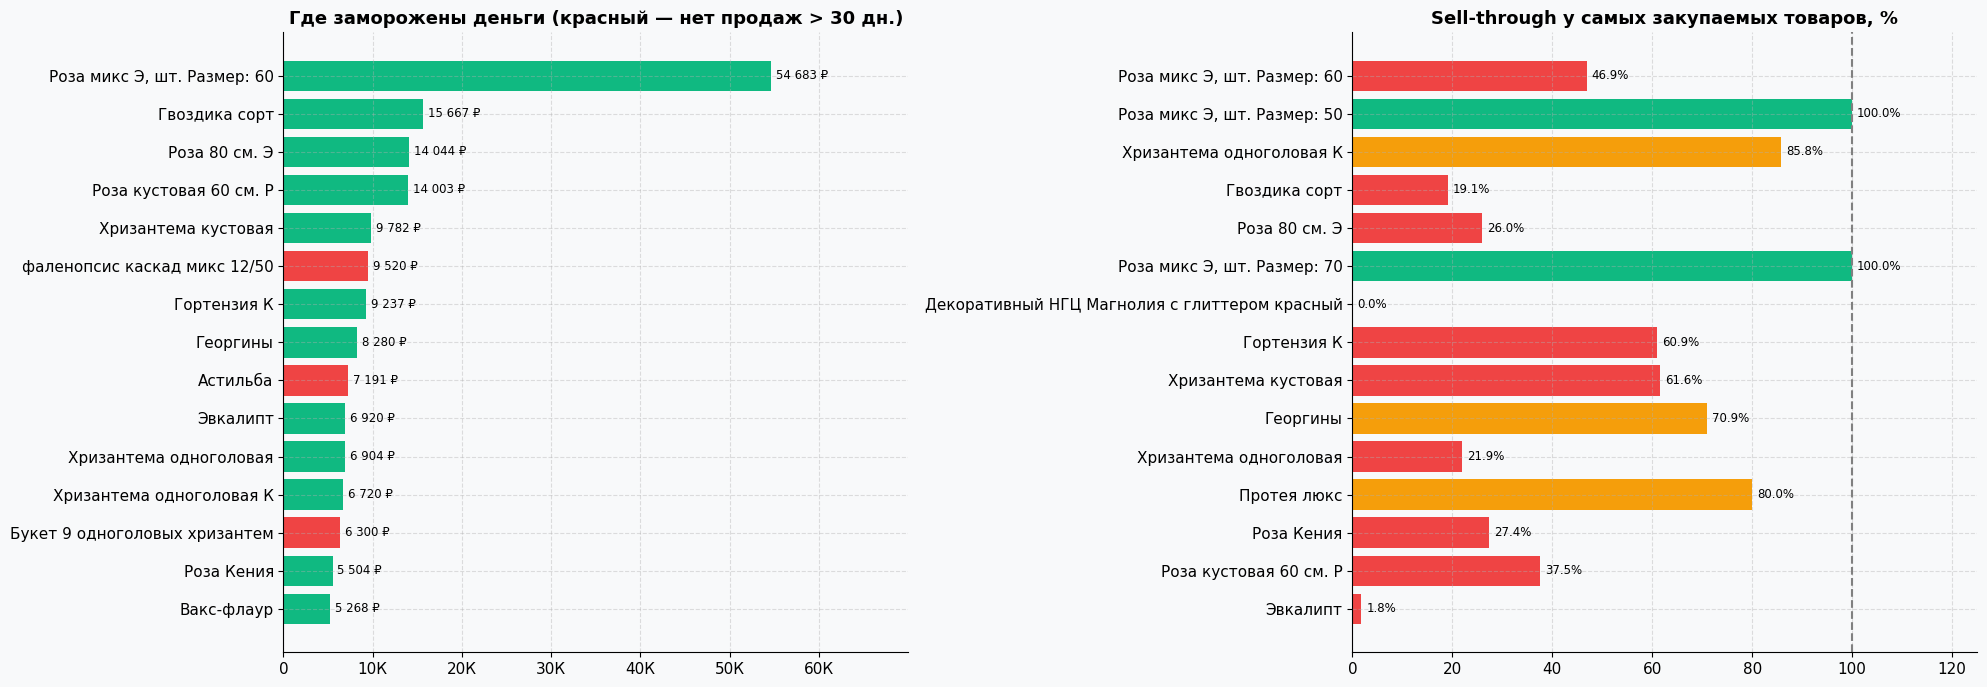

💰 Деньги в остатках: 412 415 ₽ (по себестоимости)
🧊 Из них у товаров без движения > 30 дн.: 182 335 ₽ (44%), позиций: 160

Топ «мёртвых» остатков:
                        Товар  Кон. остаток Остаток, ₽  Дней без продаж
 фаленопсис каскад микс 12/50           7.0    9 520 ₽              NaN
                     Астильба         101.0    7 191 ₽              NaN
Букет 9 одноголовых хризантем           7.0    6 300 ₽              NaN
                        Каллы          45.0    5 160 ₽              NaN
               антуриум 23/40           3.0    4 800 ₽              NaN
                      Матиола          56.0    4 525 ₽              NaN
                    Гиперекум          38.0    3 847 ₽              NaN
                    Танацетум          28.0    3 811 ₽              NaN
                Каллы высокие          31.0    3 664 ₽              NaN
                  Георгина 12          21.0    3 659 ₽              NaN
           Драцена Фраг 17/60           2.0    3 380 ₽       

In [18]:
last_sale = df_s.groupby('Товар')['Дата'].max().rename('Последняя продажа')
st = stock.merge(last_sale, on='Товар', how='left')
st['Дней без продаж'] = (_dmax - st['Последняя продажа']).dt.days
st['Было в наличии'] = st['Нач. остаток'].clip(lower=0) + st['Приход, шт']
st['Sell-through, %'] = np.where(st['Было в наличии'] > 0, st['Расход, шт'] / st['Было в наличии'] * 100, np.nan)

has_stock = st['Кон. остаток'] > 0
dead = st[has_stock & ((st['Дней без продаж'] > SLOW_DAYS) | st['Дней без продаж'].isna())].copy()
frozen_total = st.loc[has_stock, 'Остаток, ₽'].sum()
dead_total = dead['Остаток, ₽'].sum()

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
top_stock = st[has_stock].nlargest(TOP_N, 'Остаток, ₽')[::-1]
cols = [ABC_COLORS['C'] if (r['Дней без продаж'] > SLOW_DAYS or pd.isna(r['Дней без продаж'])) else ABC_COLORS['A']
        for _, r in top_stock.iterrows()]
barh_labels(axes[0], top_stock['Товар'], top_stock['Остаток, ₽'], cols)
axes[0].set_title(f'Где заморожены деньги (красный — нет продаж > {SLOW_DAYS} дн.)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))

big_buy = st[st['Приход, ₽'] > 0].nlargest(TOP_N, 'Приход, ₽')[::-1]
vals = big_buy['Sell-through, %'].fillna(0)
cc = [ABC_COLORS['A'] if v >= 90 else ABC_COLORS['B'] if v >= 70 else ABC_COLORS['C'] for v in vals]
barh_labels(axes[1], big_buy['Товар'], vals, cc, fmt=pct)
axes[1].axvline(100, color='gray', linestyle='--')
axes[1].set_xlim(0, 125)
axes[1].set_title('Sell-through у самых закупаемых товаров, %')
plt.tight_layout()
plt.show()

print(f'💰 Деньги в остатках: {rub(frozen_total)} (по себестоимости)')
print(f'🧊 Из них у товаров без движения > {SLOW_DAYS} дн.: {rub(dead_total)} ({dead_total / frozen_total * 100 if frozen_total else 0:.0f}%), позиций: {len(dead)}')
print('\nТоп «мёртвых» остатков:')
t = dead.nlargest(12, 'Остаток, ₽')[['Товар', 'Кон. остаток', 'Остаток, ₽', 'Дней без продаж']].copy()
t['Остаток, ₽'] = t['Остаток, ₽'].map(rub)
print(t.to_string(index=False))

lowst = st[(st['Приход, ₽'] > st['Приход, ₽'].median()) & (st['Sell-through, %'] < 70)].sort_values('Приход, ₽', ascending=False)
print(f'\n📉 Крупные закупки с оборачиваемостью ниже 70% (риск списаний): {len(lowst)}')
t = lowst.head(10)[['Товар', 'Приход, шт', 'Расход, шт', 'Sell-through, %']].copy()
t['Sell-through, %'] = t['Sell-through, %'].map(pct)
print(t.to_string(index=False))

neg = st[st['Кон. остаток'] < 0]
print(f'\n⛔ Отрицательные остатки: {len(neg)} товаров')
if len(neg):
    print(neg[['Товар', 'Приход, шт', 'Расход, шт', 'Кон. остаток']].head(10).to_string(index=False))

## 🔮 19. Простой прогноз выручки

Сравниваем три простых способа предсказать день: **среднее по этому же дню недели за 8 недель**, **«как неделю назад»** и **среднее за последние 28 дней**. Каждый проверяется на прошлом (бэктест на последних 28 днях), а прогноз вперёд строится тем способом, который ошибался меньше всего. Так мы не доверяем модели просто потому, что она «умнее выглядит».

Модель **не знает про праздники** — к ним смотрите раздел 8.

🧪 Бэктест на последних 7 днях. Ошибка WAPE (меньше — лучше):
   Модель                        66.6%
   Наивный: неделю назад         66.6%
   Наивный: среднее 28 дн.       33.6%
   → лучшая из трёх: «Наивный: среднее 28 дн.» — именно её и используем для прогноза ниже
   Ошибка по неделям (суммы за 7 дней) у лучшей модели: 18.3% — недельный итог точнее дневных значений


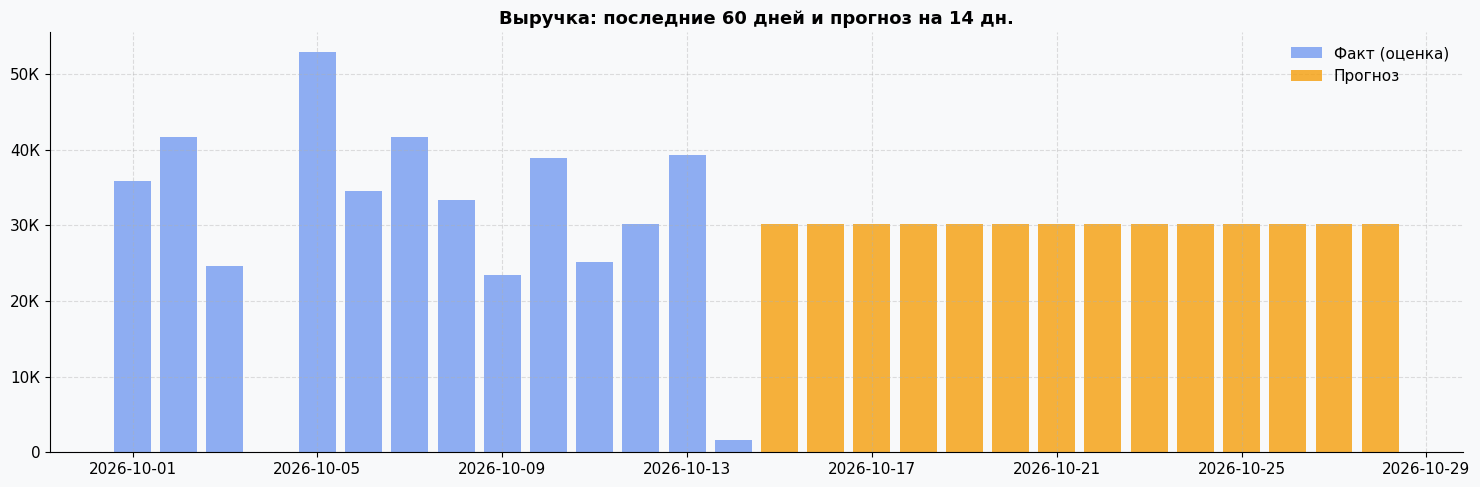


📅 Прогноз выручки на 14 дней: 423 207 ₽  (≈ 30 229 ₽ в день)
   Это ориентир для планирования закупок, а не точное число: данных меньше года, в них есть дни без чеков, а спрос на цветы скачет от праздников и погоды.


In [19]:
series = daily.set_index('Дата')['Выручка']

def predict_dow(hist, target, weeks=8):
    same = hist[(hist.index.dayofweek == target.dayofweek) & (hist.index < target)]
    return same.tail(weeks).mean()

# ---------- бэктест ----------
bt_days = min(28, max(len(series) // 4, 7))
test_idx = series.index[-bt_days:]
res = pd.DataFrame(index=test_idx)
res['Факт'] = series.loc[test_idx]
res['Модель'] = [predict_dow(series, d) for d in test_idx]
res['Наивный: неделю назад'] = [series.get(d - pd.Timedelta(days=7), np.nan) for d in test_idx]
res['Наивный: среднее 28 дн.'] = [series[series.index < d].tail(28).mean() for d in test_idx]

def wape(a, p):
    m = a.notna() & p.notna()
    return (a[m] - p[m]).abs().sum() / a[m].sum() * 100

metrics = {c: wape(res['Факт'], res[c]) for c in ['Модель', 'Наивный: неделю назад', 'Наивный: среднее 28 дн.']}
print(f'🧪 Бэктест на последних {bt_days} днях. Ошибка WAPE (меньше — лучше):')
for k, v in metrics.items():
    print(f'   {k:<28} {v:5.1f}%')
best = min(metrics, key=metrics.get)
print(f'   → лучшая из трёх: «{best}» — именно её и используем для прогноза ниже')

# ошибка на уровне недели (суммы за 7 дней) всегда меньше, чем по отдельным дням
wk_a = res['Факт'].rolling(7).sum()
wk_p = res[best].rolling(7).sum()
wk_err = wape(wk_a.dropna(), wk_p.reindex(wk_a.dropna().index))
print(f'   Ошибка по неделям (суммы за 7 дней) у лучшей модели: {wk_err:.1f}% — недельный итог точнее дневных значений')

# ---------- прогноз вперёд лучшим из методов ----------
def forecast_day(d):
    if best == 'Наивный: среднее 28 дн.':
        return series.tail(28).mean()
    if best == 'Наивный: неделю назад':
        return predict_dow(series, d, weeks=1)
    return predict_dow(series, d)

future = pd.date_range(_dmax + pd.Timedelta(days=1), periods=FORECAST_DAYS, freq='D')
fc = pd.Series([forecast_day(d) for d in future], index=future)

fig, ax = plt.subplots(figsize=(15, 5))
hist_show = series.tail(60)
ax.bar(hist_show.index, hist_show.values, color=PALETTE[0], alpha=0.5, label='Факт (оценка)')
ax.bar(fc.index, fc.values, color=PALETTE[2], alpha=0.8, label='Прогноз')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub))
ax.set_title(f'Выручка: последние 60 дней и прогноз на {FORECAST_DAYS} дн.')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f'\n📅 Прогноз выручки на {FORECAST_DAYS} дней: {rub(fc.sum())}  (≈ {rub(fc.mean())} в день)')
print('   Это ориентир для планирования закупок, а не точное число: данных меньше года, в них есть дни без чеков, '
      'а спрос на цветы скачет от праздников и погоды.')
nxt = [(n, d) for y in (_dmax.year, _dmax.year + 1) for n, d, _ in holidays_for_year(y) if future[0] <= d <= future[-1] + pd.Timedelta(days=3)]
if nxt:
    print('🎁 Ближайшие праздники рядом с прогнозом (модель их не учитывает): ' + ', '.join(f'{n} ({d:%d.%m})' for n, d in nxt))

## 🤝 20. Опт, заказы и контрагенты (дополнительные файлы)

Файлы «реализации», «прибыль» и «себестоимость» — это не чеки, а **документы и заказы**. Они нужны, чтобы увидеть оптовых и заказных клиентов. Если файлов нет или они пустые — ячейка просто это сообщит.

In [20]:
def money_cols(d, cols):
    for c in cols:
        if c in d.columns:
            d[c] = to_num(d[c])
    return d

# ---------- Прибыль по контрагентам ----------
p = find_file('прибыл')
if p:
    cp = read_csv_smart(p)
    cp.columns = [str(c).strip() for c in cp.columns]
    cp = cp.loc[:, ~cp.columns.str.startswith('Unnamed')]
    cp = money_cols(cp, ['Выручка', 'Себестоимость', 'Прибыль', 'Рентабельность'])
    cp = cp.dropna(subset=['Контрагент'])
    print(f'💼 Прибыль по контрагентам ({os.path.basename(p)}): {len(cp)} контрагентов')
    if len(cp):
        t = cp.sort_values('Прибыль', ascending=False).copy()
        for c in ['Выручка', 'Себестоимость', 'Прибыль']:
            t[c] = t[c].map(rub)
        t['Рентабельность'] = t['Рентабельность'].map(pct)
        print(t.to_string(index=False))
else:
    print('ℹ️ Файл «прибыль» не найден — пропускаем.')

# ---------- Заказы покупателей ----------
p = find_file('себестоим')
if p:
    od = read_csv_smart(p)
    od.columns = [str(c).strip() for c in od.columns]
    od = od.loc[:, ~od.columns.str.startswith('Unnamed')]
    od = money_cols(od, ['Сумма документа', 'Выручка', 'Себестоимость', 'Прибыль', 'Рентабельность'])
    od = od.dropna(subset=['Заказ покупателя'])
    od['Дата'] = pd.to_datetime(od['Заказ покупателя'].str.extract(r'от\s+(\d{2}\.\d{2}\.\d{4})')[0], format='%d.%m.%Y', errors='coerce')
    print(f'\n📋 Заказы покупателей ({os.path.basename(p)}): {len(od)} шт., выручка {rub(od["Выручка"].sum())}, '
          f'прибыль {rub(od["Прибыль"].sum())}')
    if len(od):
        t = od.sort_values('Дата')[['Заказ покупателя', 'Контрагент', 'Выручка', 'Себестоимость', 'Прибыль', 'Рентабельность']].copy()
        for c in ['Выручка', 'Себестоимость', 'Прибыль']:
            t[c] = t[c].map(rub)
        t['Рентабельность'] = t['Рентабельность'].map(pct)
        print(t.to_string(index=False))
else:
    print('ℹ️ Файл «себестоимость» не найден — пропускаем.')

# ---------- Реализации (документы с шапкой и строками) ----------
p = find_file('реализац')
if p:
    rz = read_csv_smart(p)
    rz.columns = [str(c).strip() for c in rz.columns]
    rz = rz.loc[:, ~rz.columns.str.startswith('Unnamed')]
    head = rz[rz['Номер'].notna()]
    print(f'\n📑 Реализации ({os.path.basename(p)}): документов {len(head)}')
    if len(head):
        h = head[['Номер', 'Дата', 'Контрагент', 'Сумма', 'Маржа']].copy()
        h['Сумма'] = to_num(h['Сумма']).map(rub)
        h['Маржа'] = to_num(h['Маржа']).map(rub)
        print(h.to_string(index=False))
    lines_rz = rz[rz['Товар'].notna()]
    if len(lines_rz):
        print('\n   Состав документов (строки):')
        lr = lines_rz[['Товар', 'Кол-во', 'Цена', 'Сумма', 'Маржа']].copy()
        print(lr.to_string(index=False))
else:
    print('ℹ️ Файл «реализации» не найден — пропускаем.')

print('\n⚠️ Опта в этих выгрузках пока очень мало (единичные документы) — выводов по оптовым клиентам делать рано. '
      'Для анализа опта выгрузите реализации и заказы за весь период.')

💼 Прибыль по контрагентам (Отчет по прибыли.csv): 2 контрагентов
Контрагент Выручка Себестоимость Прибыль Рентабельность
    Яндекс 2 166 ₽       1 101 ₽ 1 065 ₽          49.2%
     Алена   500 ₽         220 ₽   280 ₽          56.0%

📋 Заказы покупателей (Себестоимость по заказам.csv): 0 шт., выручка 0 ₽, прибыль 0 ₽

📑 Реализации (Отчет по реализациям.csv): документов 0

⚠️ Опта в этих выгрузках пока очень мало (единичные документы) — выводов по оптовым клиентам делать рано. Для анализа опта выгрузите реализации и заказы за весь период.


## 📋 21. Итоговое резюме

In [21]:
best_cat = cat.sort_values('Выручка', ascending=False).iloc[0]
# «Услуги флориста» — не товар (себестоимость ≈ 0), поэтому в рейтинг маржинальных категорий не берём
best_margin_cat = cat[(cat['Выручка'] > cat['Выручка'].sum() * 0.02) & (cat['Категория'] != 'Услуги флориста')].sort_values('Маржа, %', ascending=False).iloc[0]
top1 = abc_rev.iloc[0]
a_cnt = int((abc_rev['Класс'] == 'A').sum())
best_dow = DAYS_RU[int(dow['Выручка'].idxmax())]
peak_h = int(by_hour['Выручка'].idxmax())
if len(pairs):
    p_lift = pairs.sort_values('Лифт', ascending=False).iloc[0]
    p_freq = pairs.sort_values('Вместе', ascending=False).iloc[0]
    pair_txt = f'{p_freq["Товар A"]} + {p_freq["Товар B"]} ({int(p_freq["Вместе"])} чеков)'
    pair_lift_txt = f'{p_lift["Товар A"]} + {p_lift["Товар B"]} (лифт {p_lift["Лифт"]:.1f})'
else:
    pair_txt = pair_lift_txt = '—'
hol_txt = f'{hol.sort_values("× к обычному дню", ascending=False).iloc[0]["Праздник"]} (×{hol["× к обычному дню"].max():.1f})' if len(hol) else '—'

lines_out = [
    f'ИТОГИ ЗА ПЕРИОД {_dmin.date()} — {_dmax.date()}',
    '=' * 66,
    f'Выручка (оценка):        {rub(total_rev)}',
    f'Маржа:                   {rub(total_margin)}  ({pct(margin_pct)}; без услуг {pct(core_margin_pct)})',
    f'Чеков / средний чек:     {num(n_checks)} / {rub(avg_check)}',
    f'Позиций в чеке:          {items_per_check:.2f}  (одна позиция в {single:.0f}% чеков)',
    '-' * 66,
    f'Главная категория:       {best_cat["Категория"]} ({best_cat["Доля выручки, %"]:.0f}% выручки)',
    f'Самая маржинальная:      {best_margin_cat["Категория"]} ({best_margin_cat["Маржа, %"]:.0f}%)',
    f'Топ-товар по выручке:    {top1["Товар"]} ({rub(top1["Выручка"])})',
    f'Товаров класса A:        {a_cnt} из {len(abc_rev)} дают 80% выручки',
    f'Самая частая пара:      {pair_txt}',
    f'Самая сильная связь:    {pair_lift_txt}',
    '-' * 66,
    f'Лучший день недели:      {best_dow}; лучший час по выручке: {peak_h}:00',
    f'Главный праздник:        {hol_txt}',
    f'Деньги в остатках:       {rub(frozen_total)}, из них «мёртвые»: {rub(dead_total)}',
    f'Прогноз на {FORECAST_DAYS} дн.:        {rub(fc.sum())}',
]
print('\n'.join(lines_out))

print("""
ЧТО ДЕЛАТЬ ДАЛЬШЕ
1. Допродажи: у большинства чеков одна позиция — договоритесь о стандартной фразе «добавить открытку/упаковку/зелень».
2. Цены: пересмотрите крупные товары с маржой ниже цели (раздел 17).
3. Остатки: «мёртвые» позиции — в акцию или в готовые букеты до списания (раздел 18).
4. Праздники: закупку к 14 февраля, 8 марта, Дню матери и Новому году стройте по спискам из раздела 8.
5. Данные: исправьте нулевые себестоимости и отрицательные остатки — иначе маржа и остатки искажены.
6. Точность: выгрузите продажи с суммой по каждой позиции чека — тогда выручка по дням и часам станет точной, а не оценочной.
""")

ИТОГИ ЗА ПЕРИОД 2026-10-01 — 2026-10-14
Выручка (оценка):        423 207 ₽
Маржа:                   217 331 ₽  (51.4%; без услуг 48.1%)
Чеков / средний чек:     248 / 1 706 ₽
Позиций в чеке:          2.16  (одна позиция в 56% чеков)
------------------------------------------------------------------
Главная категория:       Срез: розы (45% выручки)
Самая маржинальная:      Срез: тюльпаны (57%)
Топ-товар по выручке:    Роза микс Э, шт. Размер: 60 (75 926 ₽)
Товаров класса A:        19 из 72 дают 80% выручки
Самая частая пара:      Альстрамерия + Хризантема кустовая (9 чеков)
Самая сильная связь:    Альстрамерия + Хризантема кустовая (лифт 3.6)
------------------------------------------------------------------
Лучший день недели:      Пн; лучший час по выручке: 18:00
Главный праздник:        —
Деньги в остатках:       412 415 ₽, из них «мёртвые»: 182 335 ₽
Прогноз на 14 дн.:        423 207 ₽

ЧТО ДЕЛАТЬ ДАЛЬШЕ
1. Допродажи: у большинства чеков одна позиция — договоритесь о стандартной фра